# March Madness: Comparing Four Classification Models
### SYDE 522 · Group 25

**Question:** Which model best predicts tournament-game winners using tournament seed and KenPom statistics?

- Run cells from top to bottom with Python 3.10+ and the packages in `requirements.txt`.
- The supplied `data/` folder must be beside the notebook or in the parent of the Git checkout.
- This saved notebook includes a full run and its test results. `RUN_FINAL_TEST = True` generates test plots; `False` skips them during a new run.
- Models use the same four inputs, chronological splits, and calibration procedure.

---
## Initial Imports

Uncomment the `%pip` line only if imports fail. Restart the kernel after installation if requested. All models run on a CPU; no GPU is required.


In [1]:
# Uncomment and run once if your environment needs these packages:
# %pip install -r requirements.txt


In [2]:
from pathlib import Path
import hashlib
import json
import platform
import re
import unicodedata
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix, brier_score_loss
from sklearn.exceptions import ConvergenceWarning

sns.set_theme(style="whitegrid", context="notebook", palette=["#276B80", "#C97859", "#6D597A", "#6E9277"])
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

MODEL_COLORS = dict(zip(["Logistic regression", "RBF SVM", "Random forest", "Neural network (MLP)"],
                            ["#276B80", "#C97859", "#6D597A", "#6E9277"]))
from matplotlib.ticker import PercentFormatter


Python 3.12.0 | pandas 2.3.3 | scikit-learn 1.7.2


### Experiment settings

| Setting | Meaning |
|:--|:--|
| `MODE = "full"` | Five validation seasons: 2017–2019, 2021–2022; four configurations per model |
| `MODE = "quick"` | Two validation seasons: 2021–2022; two configurations per model |
| `RUN_SEEDS = [522, 523, 524]` | Arbitrary integer starting points for reproducible random-number generation; three repeated fits in full mode (522 only in quick mode) |
| `TEST_YEARS = [2023, 2024, 2025]` | The **test set**, kept out of model selection |
| `RUN_FINAL_TEST = True` | Run test evaluation and generate its plots; already enabled in this notebook |

Random seeds have no basketball meaning. Tournament seeds (1–16) describe teams' bracket seeding and are a different concept. Repeating fits measures sensitivity to randomness; deterministic methods can produce identical results.

In [3]:
# Edit this path only if the notebook is opened from a different working folder.
# Locate data from either the original folder or the nested Git checkout.
DATA_ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent, Path.cwd() / "output/march-madness"]
PROJECT_DIR = next((p for p in DATA_ROOT_CANDIDATES if (p / "data/kenpom").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Place data/kenpom and data/competition beside the notebook, "
                            "or run from the supplied project folder.")

DATA_DIR = PROJECT_DIR / "data"
MODE = "full"                    # "quick" first; "full" for the report
RUN_FINAL_TEST = True             # change only after development decisions are frozen
MASTER_SEED = 522
START_YEAR, END_YEAR = 2003, 2025
TEST_YEARS = [2023, 2024, 2025]
CALIBRATION_SEASONS = 2
assert MODE in {"quick", "full"}
VALIDATION_YEARS = [2021, 2022] if MODE == "quick" else [2017, 2018, 2019, 2021, 2022]
RUN_SEEDS = [522] if MODE == "quick" else [522, 523, 524]
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
OUT = PROJECT_DIR / "results" / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
FEATURE_SETS = {
    "Seeds + stats": ["Seed_diff", "AdjOE_diff", "AdjDE_diff", "AdjTempo_diff"],
}
MODEL_NAMES = ["Logistic regression", "RBF SVM", "Random forest", "Neural network (MLP)"]
print("Project:", PROJECT_DIR)
print("Results:", OUT)
print("Mode:", MODE, "| Validation:", VALIDATION_YEARS, "| Repeats:", RUN_SEEDS)

Project: /Users/saathanachandrakumar/Documents/syde_522_project/march-madness
Results: /Users/saathanachandrakumar/Documents/syde_522_project/march-madness/results/20261122T231801609525Z_full
Mode: full | Validation: [2017, 2018, 2019, 2021, 2022] | Repeats: [522, 523, 524]


## Data Preparation

Build one shared dataset and evaluation protocol for all four methods.

### KenPom data

**What it is:** Ken Pomeroy's team-level college basketball ratings. The supplied file is `INT _ KenPom _ Summary (Pre-Tournament).csv`.

| Column | Meaning | Model input |
|:--|:--|:--|
| `Seed` | Tournament seed (lower is better); not a KenPom rating | `Seed_A − Seed_B` |
| `AdjOE` | Adjusted points scored per 100 possessions (higher is better) | `AdjOE_A − AdjOE_B` |
| `AdjDE` | Adjusted points allowed per 100 possessions (lower is better) | `AdjDE_A − AdjDE_B` |
| `AdjTempo` | Adjusted possessions per 40 minutes (pace) | `AdjTempo_A − AdjTempo_B` |

- **Why:** efficiency and pace describe teams beyond bracket seed. We retain all four inputs and omit the seeds-only experiment to focus on comparing algorithms. This means we no longer estimate the incremental benefit of adding statistics.
- **Where:** match `Season`/`TeamName` to team IDs, join both teams into each game, then calculate the four differences. Every model uses this same input matrix.
- **Outcome:** Kaggle tournament results supply who won; KenPom supplies predictors.
- **Timing:** use 2003–2025, excluding 2020. The file is labelled pre-tournament but has no capture timestamp; verify snapshot provenance before claiming there is no tournament-information leakage.

Definitions: [KenPom glossary](https://kenpom.com/blog/ratings-glossary/). The manifest records the input file hash.

### Report paragraph

KenPom is Ken Pomeroy’s college basketball rating system. This study uses the supplied pre-tournament-labelled team-season file for 2003–2025, excluding 2020. Predictors are tournament seed, adjusted offensive efficiency (points scored per 100 possessions), adjusted defensive efficiency (points allowed per 100 possessions), and adjusted tempo (possessions per 40 minutes). Seed is a tournament designation rather than a KenPom rating. The statistics describe team strength and pace beyond bracket seeding. Records are matched to Kaggle team identifiers and joined to each tournament game; all four inputs are calculated as Team A minus Team B. Logistic regression, RBF SVM, random forest, and MLP use the same four inputs, with outcomes taken from Kaggle results. Chronological validation selects hyperparameters, followed by testing on 2023–2025. The current comparison does not include a seeds-only baseline. The source file is labelled pre-tournament, but its snapshot timing requires independent verification before making a leakage-free claim.

---
### Part 1 — Load the source files

The KenPom source supplies **team-season predictors**. The competition source supplies **game-level outcomes**. These are different observation units and must be joined carefully.

The loader stops with a useful message if a file is missing or if multiple copies make the selection ambiguous. It does not download restricted files or access your Kaggle credentials.


In [4]:
def find_file(name, required=True):
    matches = sorted(DATA_DIR.rglob(name))
    if len(matches) > 1:
        raise ValueError(f"Multiple copies of {name}. Keep one under data/: {matches}")
    if not matches:
        if required:
            raise FileNotFoundError(
                f"Missing {name}. Download and unzip the competition data, then place it in "
                f"{DATA_DIR / 'competition'}. See Start here above."
            )
        return None
    return matches[0]

In [5]:
paths = {
    "kenpom": find_file("INT _ KenPom _ Summary (Pre-Tournament).csv"),
    "results": find_file("MNCAATourneyCompactResults.csv"),
    "teams": find_file("MTeams.csv"),
    "spellings": find_file("MTeamSpellings.csv", required=False),
}
kenpom_raw = pd.read_csv(paths["kenpom"])
results_raw = pd.read_csv(paths["results"])
teams = pd.read_csv(paths["teams"])
spellings = (pd.read_csv(paths["spellings"], encoding="latin-1")
             if paths["spellings"] else pd.DataFrame(columns=["TeamNameSpelling", "TeamID"]))
if paths["spellings"] is None:
    print("Optional MTeamSpellings.csv is absent: more manual team mappings may be needed.")
display(pd.DataFrame([
    {"source": key, "file": path.name, "bytes": path.stat().st_size}
    for key, path in paths.items() if path is not None
]))

,source,file,bytes
0,kenpom,INT _ KenPom _ Summary (Pre-Tournament).csv,821764
1,results,MNCAATourneyCompactResults.csv,77711
2,teams,MTeams.csv,10056
3,spellings,MTeamSpellings.csv,22792


### Part 2 — Pre-process and clean the data

- Select the study seasons and required columns; convert predictors to numeric values.
- Check for duplicate records, invalid games, missing seasons, and missing predictors.
- Require valid team mappings and tournament seeds; fit median imputation for missing statistics using training data only.
- Missing seeds for non-tournament teams are expected; they are not silently filled for tournament games.

In [6]:
RAW_FEATURES = ["Seed", "AdjOE", "AdjDE", "AdjTempo"]
required_k = {"Season", "TeamName", *RAW_FEATURES}
required_r = {"Season", "DayNum", "WTeamID", "LTeamID"}
assert required_k <= set(kenpom_raw.columns), "KenPom columns do not match the expected schema."
assert required_r <= set(results_raw.columns), "Tournament result columns are missing."
assert {"TeamID", "TeamName"} <= set(teams.columns)

In [7]:
kenpom = kenpom_raw.loc[
    kenpom_raw.Season.between(START_YEAR, END_YEAR) & kenpom_raw.Season.ne(2020),
    ["Season", "TeamName", *RAW_FEATURES]
].copy()
games = results_raw.loc[
    results_raw.Season.between(START_YEAR, END_YEAR) & results_raw.Season.ne(2020)
].copy()
for col in RAW_FEATURES:
    kenpom[col] = pd.to_numeric(kenpom[col], errors="coerce")
assert not kenpom.duplicated(["Season", "TeamName"]).any(), "Duplicate team-season rows."
assert not games.duplicated(["Season", "DayNum", "WTeamID", "LTeamID"]).any(), "Duplicate games."
assert games.WTeamID.ne(games.LTeamID).all()
assert set(TEST_YEARS + VALIDATION_YEARS) <= set(games.Season), "Required evaluation seasons are missing."
assert set(games.Season) <= set(kenpom.Season), "Game seasons lack predictor coverage."

,Season,TeamName,Seed,AdjOE,AdjDE,AdjTempo
0,2025,Abilene Christian,NaN,97.6324,102.0970,69.3532
1,2025,Air Force,NaN,98.9012,111.4670,64.3683
2,2025,Akron,13.0,113.6890,107.1090,71.3708
3,2025,Alabama,2.0,126.5110,96.5798,74.8553
4,2025,Alabama A&M,NaN,92.0141,115.5150,70.9783


,missing_count,missing_fraction
Seed,6162,0.8072
AdjOE,0,0.0000
AdjDE,0,0.0000
AdjTempo,0,0.0000


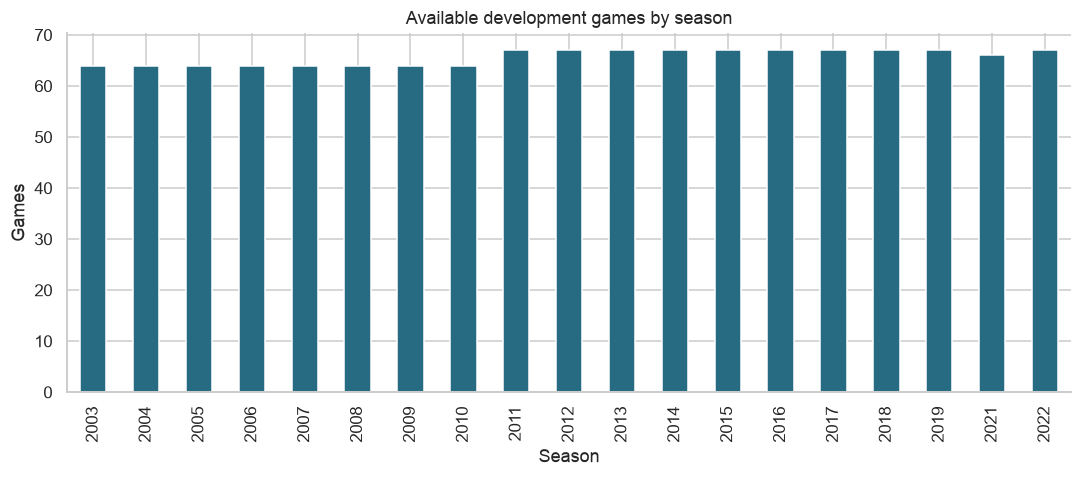

In [8]:
display(kenpom.head())
display(pd.DataFrame({"missing_count": kenpom[RAW_FEATURES].isna().sum(),
                      "missing_fraction": kenpom[RAW_FEATURES].isna().mean()}))
# Only development-season outcomes enter exploratory plots.
dev_counts = games.loc[games.Season.lt(min(TEST_YEARS))].groupby("Season").size()
fig, ax = plt.subplots()
dev_counts.plot.bar(ax=ax, color="#276B82")
ax.set(title="Available development games by season", ylabel="Games", xlabel="Season")
plt.tight_layout(); plt.show()

### Part 3 — Normalize the data

Here, **normalization means standardizing team names**, not rescaling numerical features.

- Standardize capitalization, punctuation, and spacing.
- Match names using Kaggle's official aliases and verified manual mappings.

Numerical standardization happens later inside the logistic regression, SVM, and MLP pipelines; random forest does not require it.

In [9]:
MANUAL_TEAM_IDS = {
    # Verified against MTeams/MTeamSpellings; Saint Francis is the PA team
    # (the NY team last appeared in Division I in 2023).
    "Saint Francis": 1384,
    "Mississippi Valley St.": 1290,
    "Southeast Missouri St.": 1369,
    "Texas A&M Corpus Chris": 1394,
    "Cal St. Bakersfield": 1167,
}

def normalize_name(value):
    s = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode()
    s = s.lower().replace("&", " and ")
    return re.sub(r"[^a-z0-9]", "", s)

alias_rows = teams[["TeamName", "TeamID"]].rename(columns={"TeamName": "Alias"})
if not spellings.empty:
    alias_rows = pd.concat([alias_rows, spellings[["TeamNameSpelling", "TeamID"]]
                            .rename(columns={"TeamNameSpelling": "Alias"})], ignore_index=True)
alias_rows["key"] = alias_rows.Alias.map(normalize_name)
counts = alias_rows.groupby("key").TeamID.nunique()
ambiguous_keys = set(counts[counts > 1].index)
alias_map = (alias_rows.loc[~alias_rows.key.isin(ambiguous_keys)]
             .drop_duplicates("key").set_index("key").TeamID.to_dict())
assert set(MANUAL_TEAM_IDS.values()) <= set(teams.TeamID), "A manual ID is absent from MTeams.csv."

mapped = kenpom.copy()
mapped["TeamID"] = mapped.TeamName.map(normalize_name).map(alias_map)
manual_ids = mapped.TeamName.map(MANUAL_TEAM_IDS)
mapped["TeamID"] = manual_ids.combine_first(mapped.TeamID)

# Report every seeded row that cannot be matched; do not silently discard it.
unmatched = mapped.loc[mapped.Seed.notna() & mapped.TeamID.isna(), ["Season", "TeamName", "Seed"]]
if not unmatched.empty:
    unmatched.to_csv(OUT / "unmatched_teams.csv", index=False)
    display(unmatched.head(30))
    raise ValueError("Unmatched seeded teams. Review the export and add verified MANUAL_TEAM_IDS.")

mapped = mapped.dropna(subset=["TeamID"]).copy()
mapped["TeamID"] = mapped.TeamID.astype(int)
assert not mapped.duplicated(["Season", "TeamID"]).any(), "Multiple KenPom teams map to one ID in a season."
mapped[["Season", "TeamName", "TeamID"]].to_csv(OUT / "team_mapping.csv", index=False)
print(f"Mapped {len(mapped):,} team-season rows; {len(ambiguous_keys)} ambiguous normalized aliases were excluded.")


Mapped 7,613 team-season rows; 0 ambiguous normalized aliases were excluded.


### Part 4 — Build the Game-Level Modeling Dataset

Create one row per tournament game, combining both teams’ statistics with the game outcome.

- **Team labels:** A has the lower team ID; B has the higher ID. This ordering is independent of who won.
- **Inputs:** calculate `Team A − Team B` for seed, offensive efficiency, defensive efficiency, and tempo.
- **Target:** `y_true = 1` if A won; `0` if B won.

All four models use these same inputs and outcomes. Checks ensure no games are duplicated or lost.

In [10]:
matchups = games[["Season", "DayNum", "WTeamID", "LTeamID"]].copy()
matchups["TeamA"] = np.minimum(matchups.WTeamID, matchups.LTeamID)
matchups["TeamB"] = np.maximum(matchups.WTeamID, matchups.LTeamID)
matchups["y_true"] = (matchups.WTeamID == matchups.TeamA).astype(int)
matchups["game_id"] = matchups.apply(
    lambda r: f"{int(r.Season)}_{int(r.DayNum)}_{int(r.TeamA)}_{int(r.TeamB)}", axis=1)
matchups = matchups.drop(columns=["WTeamID", "LTeamID"])
for side in ["A", "B"]:
    table = mapped[["Season", "TeamID", "TeamName", *RAW_FEATURES]].rename(
        columns={"TeamID": f"Team{side}", "TeamName": f"Name{side}",
                 **{c: f"{c}_{side}" for c in RAW_FEATURES}})
    matchups = matchups.merge(table, on=["Season", f"Team{side}"], how="left", validate="many_to_one")

In [11]:
missing_sides = matchups[["NameA", "NameB", "Seed_A", "Seed_B"]].isna().any(axis=1)
if missing_sides.any():
    matchups.loc[missing_sides].to_csv(OUT / "missing_matchup_features.csv", index=False)
    raise ValueError("Some games lack mapped teams or seeds. See missing_matchup_features.csv; fix before modeling.")
for side in ["A", "B"]:
    assert matchups[f"Seed_{side}"].between(1, 16).all(), "Unexpected seed range."
for c in RAW_FEATURES:
    matchups[f"{c}_diff"] = matchups[f"{c}_A"] - matchups[f"{c}_B"]
matchups = matchups.sort_values(["Season", "DayNum", "TeamA", "TeamB"]).reset_index(drop=True)
assert matchups.game_id.is_unique
assert len(matchups) == len(games), "Joining changed the number of games."
assert matchups.TeamA.lt(matchups.TeamB).all()
assert set(matchups.y_true) == {0, 1}
all_features = FEATURE_SETS["Seeds + stats"]
assert not np.isinf(matchups[all_features].to_numpy()).any()
matchups.to_csv(OUT / "matchups.csv", index=False)

In [12]:
development = matchups.loc[matchups.Season.lt(min(TEST_YEARS))].copy()
display(development[["Season", "NameA", "NameB", *all_features, "y_true"]].head())
print(f"{len(matchups):,} actual games; {len(development):,} development games. No games silently dropped.")

,Season,NameA,NameB,Seed_diff,AdjOE_diff,AdjDE_diff,AdjTempo_diff,y_true
0,2003,Texas Southern,UNC Asheville,0.0,-2.237,-5.8660,0.3680,0
1,2003,Arizona,Vermont,-15.0,13.588,-10.9991,8.7153,1
2,2003,Arizona St.,Memphis,3.0,1.812,2.8983,-1.4671,1
3,2003,BYU,Connecticut,7.0,-1.193,-1.0058,-5.4455,0
4,2003,Central Michigan,Creighton,5.0,-3.163,4.7823,3.5001,1


1,449 actual games; 1,248 development games. No games silently dropped.


### Part 5 — Training, calibration, validation, and testing

| Stage | Purpose |
|:--|:--|
| Base training | Learn the model and preprocessing parameters from earlier seasons |
| Calibration | Use the next two historical seasons to adjust model outputs into more reliable win probabilities |
| Validation | Compare configurations on a later season and select the lowest average log loss |
| Test set | Evaluate the selected models on unseen 2023–2025 games |

A **pipeline** combines preprocessing and a classifier. A **calibrated pipeline** adds a sigmoid probability-adjustment step fitted on separate historical data. An **uncalibrated classifier** uses its original outputs without that adjustment; for SVM, these are decision scores, not probabilities. Calibration aims to improve probability reliability but does not guarantee an improvement.

For final evaluation, base training uses 2003–2019, calibration uses 2021–2022, and testing uses 2023–2025. Models are not updated between test seasons. There was no 2020 tournament.

In [13]:
def chronological_parts(history):
    seasons = sorted(history.Season.unique())
    if len(seasons) <= CALIBRATION_SEASONS:
        raise ValueError("Insufficient historical seasons for base training plus calibration.")
    cal_years = seasons[-CALIBRATION_SEASONS:]
    base = history.loc[~history.Season.isin(cal_years)].copy()
    cal = history.loc[history.Season.isin(cal_years)].copy()
    assert base.Season.max() < cal.Season.min()
    assert base.y_true.nunique() == cal.y_true.nunique() == 2
    return base, cal

In [14]:
split_rows = []
for year in VALIDATION_YEARS:
    history = development.loc[development.Season.lt(year)]
    base, cal = chronological_parts(history)
    valid = development.loc[development.Season.eq(year)]
    assert cal.Season.max() < year
    assert set(history.game_id).isdisjoint(valid.game_id)
    split_rows.append({"validation_season": year,
                       "base_years": f"{base.Season.min()}–{base.Season.max()}",
                       "calibration_years": ", ".join(map(str, sorted(cal.Season.unique()))),
                       "base_games": len(base), "calibration_games": len(cal),
                       "validation_games": len(valid)})
splits = pd.DataFrame(split_rows)
display(splits)
splits.to_csv(OUT / "validation_splits.csv", index=False)

,validation_season,base_years,calibration_years,base_games,calibration_games,validation_games
0,2017,2003–2014,"2015, 2016",780,134,67
1,2018,2003–2015,"2016, 2017",847,134,67
2,2019,2003–2016,"2017, 2018",914,134,67
3,2021,2003–2017,"2018, 2019",981,134,66
4,2022,2003–2018,"2019, 2021",1048,133,67


### Part 6 — Evaluation metrics

| Metric | Meaning | Better result |
|:--|:--|:--|
| Log loss (primary) | Penalizes incorrect predictions, especially those assigned high probability | Lower |
| Brier score | Mean squared error of predicted win probability: mean `(p − y)²` | Lower |
| Accuracy | Fraction of correctly predicted winners using a 0.5 threshold | Higher |

**Brier score is not hinge loss.** For this binary problem it is also called *mean squared probability error* (range 0–1). Hinge loss is a margin-based loss, `max(0, 1 − y × score)` with labels −1/+1, commonly associated with SVMs. It uses decision scores rather than win probabilities. We evaluate all models with the same probability metrics.

Sources: [Brier score](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.brier_score_loss.html), [hinge loss](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.hinge_loss.html).

In [15]:
EPS = 1e-15

def evaluate(y, p):
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    assert y.shape == p.shape and len(y) > 0
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return {"log_loss": float(log_loss(y, np.clip(p, EPS, 1-EPS), labels=[0, 1])),
            "brier": float(brier_score_loss(y, p)),
            "accuracy": float(accuracy_score(y, p >= 0.5))}

def seed_pick_accuracy(frame):
    # Equal seeds use the same Team-A tie convention.
    pick_a = frame.Seed_A.le(frame.Seed_B).astype(int)
    return float(accuracy_score(frame.y_true, pick_a))

In [16]:
def prediction_rows(frame, p, model, feature_set, run_seed, candidate_id=None):
    result = frame[["Season", "game_id", "NameA", "NameB", "Seed_A", "Seed_B", "y_true"]].copy()
    result = result.rename(columns={"Season": "season"})
    result["model"], result["feature_set"] = model, feature_set
    result["run_seed"], result["candidate_id"] = run_seed, candidate_id
    result["p_A_wins"] = p
    return result

### Shared implementation and model-selection table

- **Independent variables (`X`):** four differences—tournament seed, offense, defense, and tempo—one row per game. “Seeds + stats” is the single input set retained here.
- **Dependent variable (`y`):** 1 if Team A wins; 0 if Team B wins. Team A has the lower team ID. These labels describe the two opponents in each game.
- Use scikit-learn estimators, `Pipeline`, median imputation, and sigmoid calibration; the learning algorithms are not implemented from scratch.
- A **configuration** is one set of hyperparameters. IDs 0–3 simply index these sets. Select the lowest mean validation log loss, using unrounded values; an exact tie uses the lower ID.

The former “development table” is now the **validation model-selection table**: it summarizes data used to choose settings, not final test performance.

| Column | Meaning |
|:--|:--|
| `model`, `feature_set` | Algorithm and four-input feature set |
| `candidate_id`, `parameters` | Selected configuration ID and its hyperparameters; not learned coefficients or weights |
| `mean_log_loss`, `mean_brier`, `mean_accuracy` | Average validation scores over the same seasons and random seeds; seasons receive equal weight |

Full mode averages 5 seasons × 3 runs = 15 values per configuration; quick mode averages 2 seasons × 1 run.

In [17]:
CANDIDATES, MODEL_BUILDERS = {}, {}
model_results = {}

def make_base_model(name, params, seed):
    estimator = MODEL_BUILDERS[name](params, seed)
    steps = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if name != "Random forest":
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps + [("model", estimator)])

def fit_calibrated(history, columns, name, params, seed):
    base, cal = chronological_parts(history)
    if base[columns].isna().all().any():
        raise ValueError("An entire base-training predictor is missing; inspect data rather than filling it blindly.")
    model = make_base_model(name, params, seed)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(base[columns], base.y_true)
        calibrated = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")
        calibrated.fit(cal[columns], cal.y_true)
    notes = " | ".join(sorted({str(w.message) for w in caught}))
    return calibrated, notes

In [18]:
def tune_model(name):
    cv_scores, cv_predictions = [], []
    for feature_set, columns in FEATURE_SETS.items():
        for candidate_id, params in enumerate(CANDIDATES[name]):
            for seed in RUN_SEEDS:
                for year in VALIDATION_YEARS:
                    history = development.loc[development.Season.lt(year)]
                    valid = development.loc[development.Season.eq(year)]
                    fitted, notes = fit_calibrated(history, columns, name, params, seed)
                    p = fitted.predict_proba(valid[columns])[:, list(fitted.classes_).index(1)]
                    cv_scores.append({"model": name, "feature_set": feature_set,
                        "candidate_id": candidate_id, "run_seed": seed, "season": year,
                        "warnings": notes, **evaluate(valid.y_true, p)})
                    cv_predictions.append(prediction_rows(valid, p, name, feature_set, seed, candidate_id))
        print(f"Completed: {name} · {feature_set}")
    cv_scores = pd.DataFrame(cv_scores)
    cv_predictions = pd.concat(cv_predictions, ignore_index=True)

    candidate_scores = (cv_scores.groupby(["model", "feature_set", "candidate_id"], as_index=False)
                        .agg(mean_log_loss=("log_loss", "mean"), mean_brier=("brier", "mean"),
                             mean_accuracy=("accuracy", "mean")))
    selected = (candidate_scores.sort_values(["mean_log_loss", "candidate_id"])
                .drop_duplicates(["model", "feature_set"]).reset_index(drop=True))
    selected["parameters"] = selected.apply(
        lambda r: json.dumps(CANDIDATES[r.model][int(r.candidate_id)]), axis=1)
    show_configuration_results(name, candidate_scores, selected)
    warning_rows = cv_scores.loc[cv_scores.warnings.ne("")]
    if not warning_rows.empty:
        display(warning_rows[["model", "feature_set", "season", "warnings"]].head())

    return cv_scores, cv_predictions, candidate_scores, selected

def show_configuration_results(name, candidate_scores, selected):
    results = candidate_scores.copy()
    results["parameters"] = results.candidate_id.map(lambda i: json.dumps(CANDIDATES[name][int(i)]))
    chosen_ids = set(selected.candidate_id.astype(int))
    results["selection"] = results.candidate_id.map(lambda i: "BEST — selected" if int(i) in chosen_ids else "")
    if name == "Logistic regression":
        results["C"] = results.candidate_id.map(lambda i: CANDIDATES[name][int(i)]["C"])
        results = results.sort_values("C")
    else:
        results = results.sort_values("candidate_id")
    columns = ["candidate_id", "parameters", "mean_log_loss", "mean_brier", "mean_accuracy", "selection"]
    print(f"All {name} configurations (mean validation results):")
    display(results[columns].style.hide(axis="index")
            .format({"mean_log_loss": "{:.6f}", "mean_brier": "{:.6f}", "mean_accuracy": "{:.6f}"})
            .apply(lambda row: ["background-color: #e0f0e9; color: #173d32; font-weight: bold;"
                               if row["selection"] else "" for _ in row], axis=1))
    best = selected.iloc[0]
    print(f"Best configuration: {json.dumps(CANDIDATES[name][int(best.candidate_id)])} "
          f"(candidate {int(best.candidate_id)}). Mean validation log loss: {best.mean_log_loss:.6f}. "
          "Selected using the lowest unrounded mean validation log loss; exact ties retain the lower ID.")


In [19]:
def configuration_label(name, params):
    if name == "Logistic regression":
        return f"C = {params['C']:g}"
    if name == "RBF SVM":
        return f"C = {params['C']:g}\ngamma = {params['gamma']}"
    if name == "Random forest":
        depth = "unlimited" if params['max_depth'] is None else str(params['max_depth'])
        return f"Depth: {depth}\nMin. leaf: {params['min_samples_leaf']}"
    return f"Hidden layers: {len(params['hidden_layer_sizes'])} (8 units each)\nalpha = {params['alpha']:g}"

def label_bars(ax, decimals=6):
    for container in ax.containers:
        if hasattr(container, "datavalues"):
            ax.bar_label(container, fmt=f"%.{decimals}f", label_type="center", color="white", fontsize=10)

def plot_model_validation(name):
    scores, predictions, candidates, chosen = model_results[name]
    ordered = list(range(len(CANDIDATES[name])))
    if name == "Logistic regression":
        ordered.sort(key=lambda i: CANDIDATES[name][i]["C"])
    table = candidates.set_index("candidate_id").loc[ordered]
    labels = [configuration_label(name, CANDIDATES[name][i]) for i in ordered]
    fig, axes = plt.subplots(2, 1, figsize=(10, 9))
    axes[0].bar(labels, table.mean_log_loss, color=MODEL_COLORS[name], width=0.65)
    axes[0].set(title="Configuration comparison", xlabel="Hyperparameter configuration",
                ylabel="Mean validation log loss (lower is better)")
    selected_scores = scores.loc[scores.candidate_id.eq(int(chosen.iloc[0].candidate_id))]
    seasons = selected_scores.groupby("season").log_loss.mean().reindex(VALIDATION_YEARS)
    axes[1].bar(seasons.index.astype(str), seasons.values, color=MODEL_COLORS[name], width=0.65)
    selected_label = configuration_label(name, CANDIDATES[name][int(chosen.iloc[0].candidate_id)]).replace("\n", "; ")
    axes[1].set(title=f"Selected configuration: {selected_label} — validation by season", xlabel="Validation season",
                ylabel="Mean validation log loss (lower is better)")
    for ax in axes:
        ax.set_ylim(bottom=0)
        label_bars(ax, decimals=6)
    fig.suptitle(f"{name}: validation results", fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT / f"{name.lower().replace(' ', '_')}_validation.png", bbox_inches="tight")
    plt.show()
    row = chosen.iloc[0]
    config = configuration_label(name, CANDIDATES[name][int(row.candidate_id)]).replace("\n", "; ")
    display(Markdown(f"**Takeaway:** {config} is selected because it has the lowest average "
                     f"validation log loss ({row.mean_log_loss:.6f}; ties use the lower configuration ID). "
                     f"Its seasonal mean log loss ranges from {seasons.min():.6f} to {seasons.max():.6f}, "
                     f"showing how performance varies across tournaments. Bar labels show six decimals; selection uses full precision."))


## Model Implementation — Logistic Regression

- **Method:** A simple linear relationship between the inputs and log-odds of winning.
- **Library:** [`sklearn.linear_model.LogisticRegression`](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html); not implemented from scratch.
- **Inputs:** the same four A-minus-B differences; fitting also requires the observed winner. Prediction does not require the outcome.
- **Preprocessing:** median imputation; standardization to zero mean and unit variance. All methods use separate chronological sigmoid calibration.
- **Configurations:** `C` controls regularization: smaller C means stronger regularization. Four choices: 0.01, 0.1, 1, 10 (displayed in increasing order).

### 1. Define configurations

In [20]:
def build_logistic_regression(params, seed):
    return LogisticRegression(max_iter=1500, random_state=seed, **params)

MODEL_BUILDERS['Logistic regression'] = build_logistic_regression
CANDIDATES['Logistic regression'] = [{"C": c} for c in [0.1, 1.0, 0.01, 10.0]]
if MODE == "quick":
    CANDIDATES['Logistic regression'] = CANDIDATES['Logistic regression'][:2]
display(pd.DataFrame(CANDIDATES['Logistic regression']).rename_axis("candidate_id"))

,C
candidate_id,
0,0.10
1,1.00
2,0.01
3,10.00


### 2. Fit and select

Fit each configuration on earlier seasons, calibrate on the next two, and evaluate on the validation season. Select the smallest average validation log loss.

In [21]:
# Display every configuration and highlight the one selected by validation log loss.
model_results['Logistic regression'] = tune_model('Logistic regression')


All Logistic regression configurations (mean validation results):


candidate_id,parameters,mean_log_loss,mean_brier,mean_accuracy,selection
2,"{""C"": 0.01}",0.565994,0.193846,0.700588,
0,"{""C"": 0.1}",0.563728,0.192927,0.703573,
1,"{""C"": 1.0}",0.562409,0.192408,0.700588,
3,"{""C"": 10.0}",0.562221,0.192336,0.700588,BEST — selected


Best configuration: {"C": 10.0} (candidate 3). Mean validation log loss: 0.562221. Selected using the lowest unrounded mean validation log loss; exact ties retain the lower ID.


### 3. Compare configurations

- Top: mean loss across validation seasons and runs for each configuration.
- Bottom: mean loss across runs, by validation season, for the selected configuration.
- Each bar aggregates tournament games, not individual teams. Values are printed to six decimals; smaller is better.

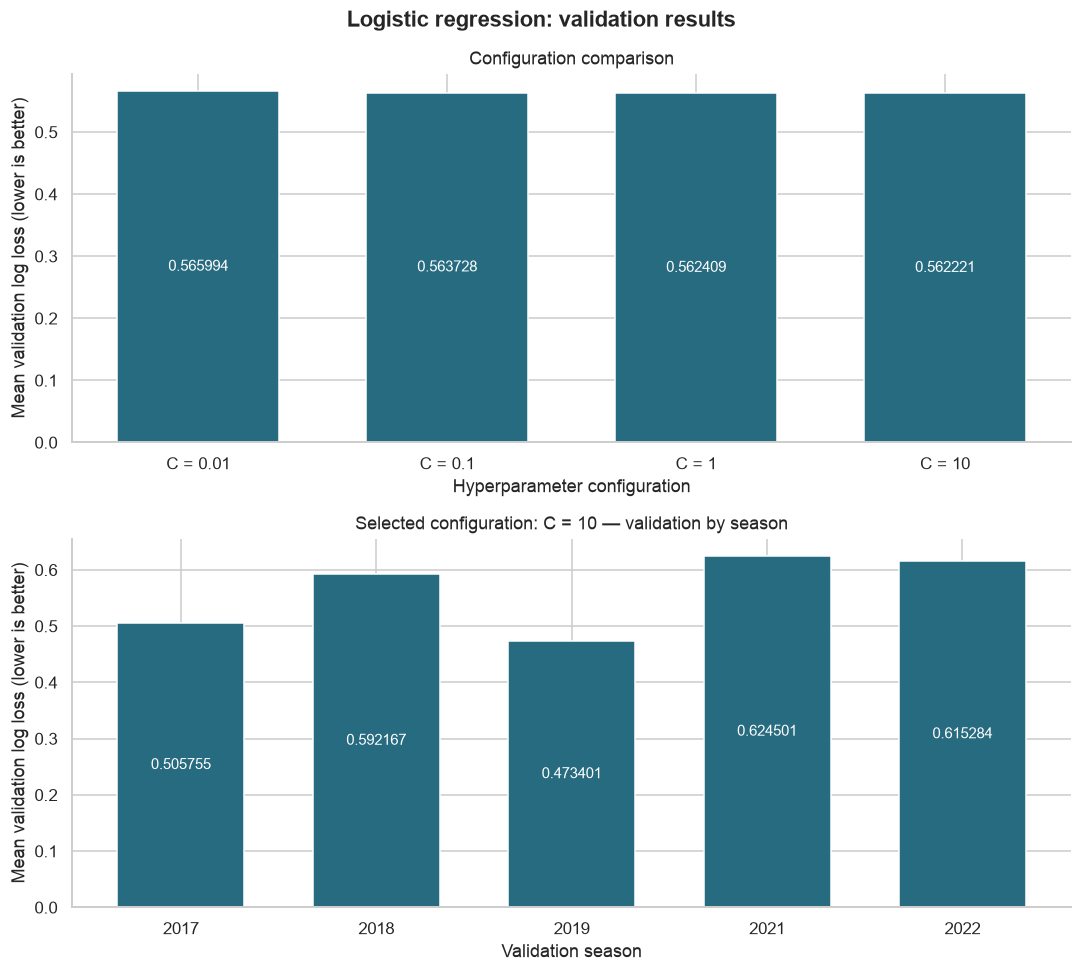

**Takeaway:** C = 10 is selected because it has the lowest average validation log loss (0.562221; ties use the lower configuration ID). Its seasonal mean log loss ranges from 0.473401 to 0.624501, showing how performance varies across tournaments. Bar labels show six decimals; selection uses full precision.

In [22]:
plot_model_validation('Logistic regression')

### How the selected logistic regression model produces probabilities

- **Example fit:** selected C = 10, evaluated on validation season 2022, with random seed 522. Earlier seasons train the model; the next two historical seasons calibrate it.
- **Horizontal axis:** the fitted model's combined score from all four standardized inputs—not one individual statistic.
- **Curves:** the original logistic probability and the probability after sigmoid calibration. The 0.5 line separates predictions of A winning from B winning.
- **Dots:** actual 2022 outcomes, at 1 for an A win and 0 for a B win. These are individual games, not probability estimates.

This explains one selected model fit. The curves are not a comparison of test performance, and this validation season also contributed to configuration selection.


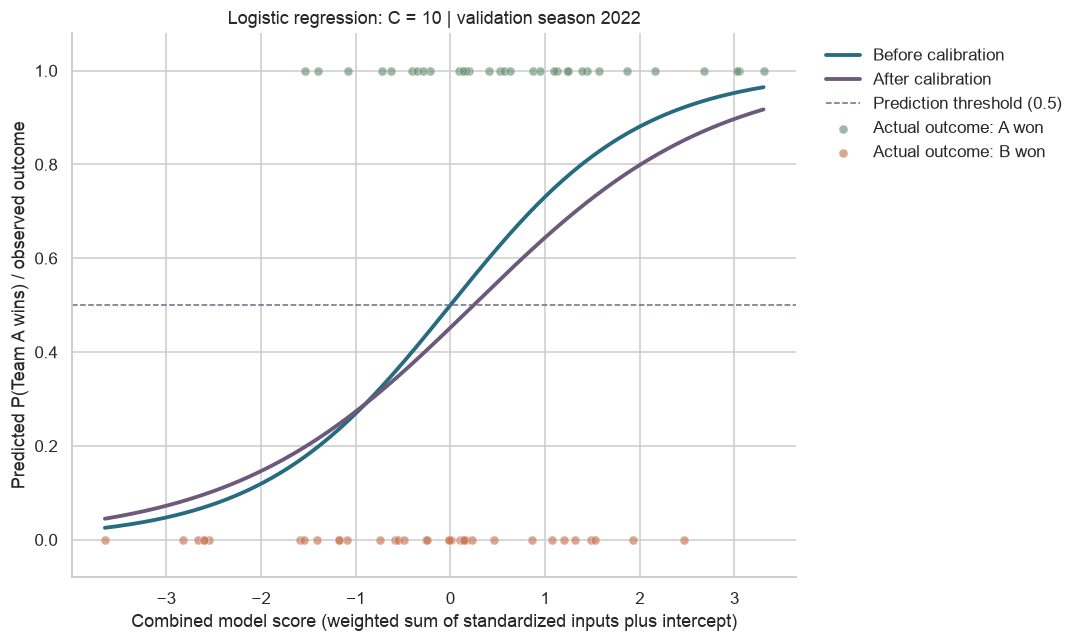

Base training: 2003–2018; calibration seasons: [2019, 2021]; validation: 2022 (67 games).


In [23]:
# Refit the selected configuration for one clearly labelled validation fold.
LR_EXAMPLE_YEAR = 2022
LR_EXAMPLE_SEED = 522
lr_selected_row = model_results["Logistic regression"][3].iloc[0]
lr_example_params = CANDIDATES["Logistic regression"][int(lr_selected_row.candidate_id)]
lr_example_columns = FEATURE_SETS["Seeds + stats"]
lr_example_history = development.loc[development.Season.lt(LR_EXAMPLE_YEAR)]
lr_example_valid = development.loc[development.Season.eq(LR_EXAMPLE_YEAR)]
lr_example_train, lr_example_cal = chronological_parts(lr_example_history)

lr_example_model = make_base_model("Logistic regression", lr_example_params, LR_EXAMPLE_SEED)
lr_example_model.fit(lr_example_train[lr_example_columns], lr_example_train.y_true)
lr_example_calibrated = CalibratedClassifierCV(FrozenEstimator(lr_example_model), method="sigmoid")
lr_example_calibrated.fit(lr_example_cal[lr_example_columns], lr_example_cal.y_true)

# Draw smooth curves over the range of combined scores observed in validation.
lr_example_scores = lr_example_model.decision_function(lr_example_valid[lr_example_columns])
lr_score_grid = np.linspace(lr_example_scores.min(), lr_example_scores.max(), 300)
lr_weights = lr_example_model.named_steps["model"].coef_[0]
lr_intercept = lr_example_model.named_steps["model"].intercept_[0]
# Construct inputs with exactly these combined scores; this is not a feature-effect plot.
assert np.dot(lr_weights, lr_weights) > 0
lr_scaled_grid = np.outer(lr_score_grid - lr_intercept, lr_weights / np.dot(lr_weights, lr_weights))
lr_grid_inputs = pd.DataFrame(lr_example_model.named_steps["scale"].inverse_transform(lr_scaled_grid),
                              columns=lr_example_columns)
assert np.allclose(lr_example_model.decision_function(lr_grid_inputs), lr_score_grid)
lr_original_p = lr_example_model.predict_proba(lr_grid_inputs)[:, list(lr_example_model.classes_).index(1)]
lr_calibrated_p = lr_example_calibrated.predict_proba(lr_grid_inputs)[:, list(lr_example_calibrated.classes_).index(1)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(lr_score_grid, lr_original_p, color="#276B80", linewidth=2.5, label="Before calibration")
ax.plot(lr_score_grid, lr_calibrated_p, color="#6D597A", linewidth=2.5, label="After calibration")
ax.axhline(0.5, color="#667085", linestyle="--", linewidth=1, label="Prediction threshold (0.5)")
for outcome, color, label in [(1, "#6E9277", "Actual outcome: A won"), (0, "#C97859", "Actual outcome: B won")]:
    mask = lr_example_valid.y_true.to_numpy() == outcome
    ax.scatter(lr_example_scores[mask], np.full(mask.sum(), outcome), color=color,
               alpha=0.65, s=35, edgecolors="white", linewidths=0.4, label=label, zorder=3)
ax.set(title=f"Logistic regression: C = {lr_example_params['C']:g} | validation season {LR_EXAMPLE_YEAR}",
       xlabel="Combined model score (weighted sum of standardized inputs plus intercept)",
       ylabel="Predicted P(Team A wins) / observed outcome", ylim=(-0.08, 1.08))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
fig.tight_layout()
fig.savefig(OUT / "logistic_regression_probability_2022.png", bbox_inches="tight")
plt.show()
print(f"Base training: {lr_example_train.Season.min()}–{lr_example_train.Season.max()}; "
      f"calibration seasons: {sorted(lr_example_cal.Season.unique().tolist())}; "
      f"validation: {LR_EXAMPLE_YEAR} ({len(lr_example_valid)} games).")


## Model Implementation — RBF Support Vector Machine

- **Method:** A nonlinear classifier using an RBF kernel.
- **Library:** [`sklearn.svm.SVC`](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html); not implemented from scratch.
- **Inputs:** the same four A-minus-B differences; fitting also requires the observed winner. Prediction does not require the outcome.
- **Preprocessing:** median imputation; standardization to zero mean and unit variance. All methods use separate chronological sigmoid calibration.
- **Configurations:** `C` controls the penalty for margin violations: larger C penalizes them more. `gamma` controls how local the kernel influence is: larger gamma gives a narrower influence. Test C = 0.5 or 2, crossed with gamma = `scale` or 0.1. `gamma="scale"` automatically sets gamma from the input data; with our four standardized features, it is approximately 0.25.

### 1. Define configurations

In [24]:
def build_rbf_svm(params, seed):
    return SVC(kernel="rbf", probability=False, random_state=seed, **params)

MODEL_BUILDERS['RBF SVM'] = build_rbf_svm
CANDIDATES['RBF SVM'] = [{"C": 0.5, "gamma": "scale"}, {"C": 2.0, "gamma": "scale"}, {"C": 0.5, "gamma": 0.1}, {"C": 2.0, "gamma": 0.1}]
if MODE == "quick":
    CANDIDATES['RBF SVM'] = CANDIDATES['RBF SVM'][:2]
display(pd.DataFrame(CANDIDATES['RBF SVM']).rename_axis("candidate_id"))

,C,gamma
candidate_id,,
0,0.5,scale
1,2.0,scale
2,0.5,0.1
3,2.0,0.1


### 2. Fit and select

Fit each configuration on earlier seasons, calibrate on the next two, and evaluate on the validation season. Select the smallest average validation log loss.

In [25]:
# Display every configuration and highlight the one selected by validation log loss.
model_results['RBF SVM'] = tune_model('RBF SVM')


All RBF SVM configurations (mean validation results):


candidate_id,parameters,mean_log_loss,mean_brier,mean_accuracy,selection
0,"{""C"": 0.5, ""gamma"": ""scale""}",0.593932,0.203031,0.691542,
1,"{""C"": 2.0, ""gamma"": ""scale""}",0.596961,0.204186,0.685617,
2,"{""C"": 0.5, ""gamma"": 0.1}",0.579173,0.197680,0.706558,BEST — selected
3,"{""C"": 2.0, ""gamma"": 0.1}",0.586008,0.200010,0.700588,


Best configuration: {"C": 0.5, "gamma": 0.1} (candidate 2). Mean validation log loss: 0.579173. Selected using the lowest unrounded mean validation log loss; exact ties retain the lower ID.


### 3. Compare configurations

- Top: mean loss across validation seasons and runs for each configuration.
- Bottom: mean loss across runs, by validation season, for the selected configuration.
- Each bar aggregates tournament games, not individual teams. Values are printed to six decimals; smaller is better.

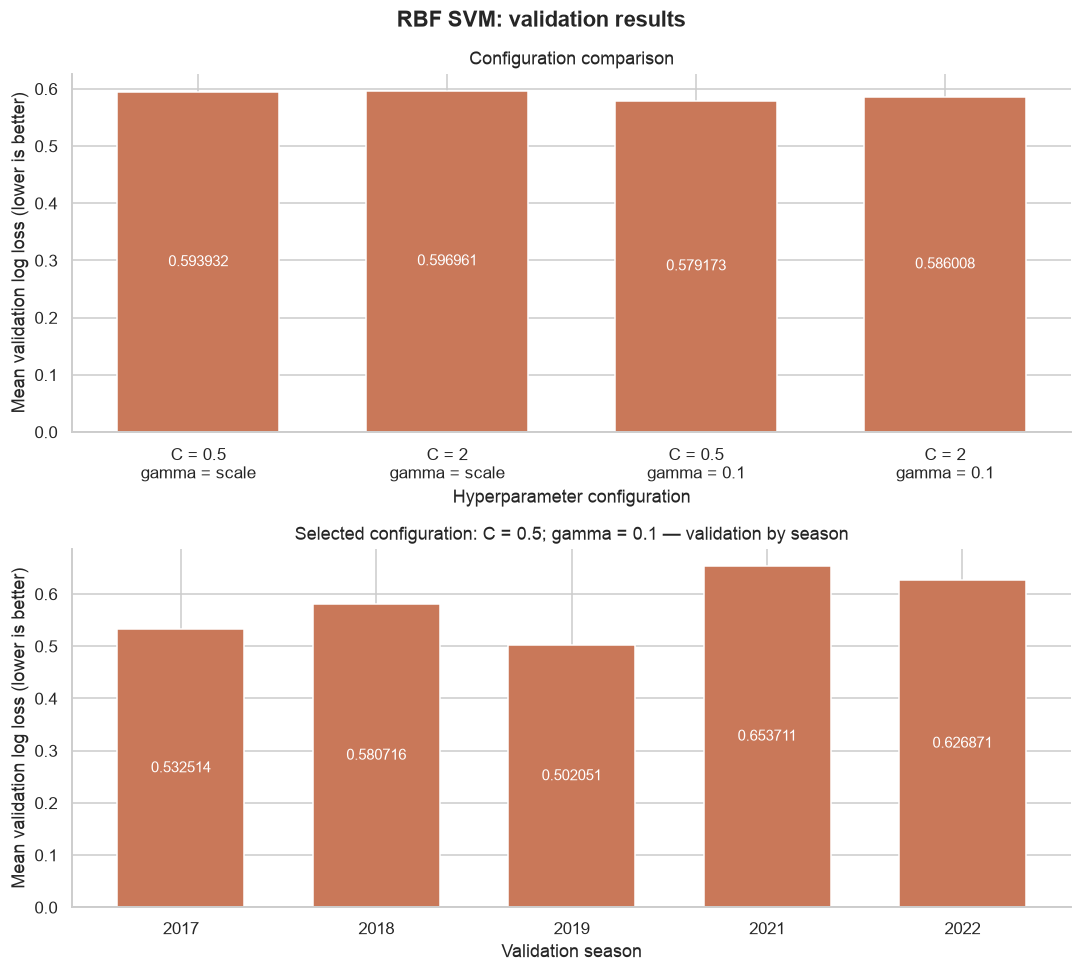

**Takeaway:** C = 0.5; gamma = 0.1 is selected because it has the lowest average validation log loss (0.579173; ties use the lower configuration ID). Its seasonal mean log loss ranges from 0.502051 to 0.653711, showing how performance varies across tournaments. Bar labels show six decimals; selection uses full precision.

In [26]:
plot_model_validation('RBF SVM')

### Selected SVM decision regions

- **Background:** two predicted-winner regions, separated where calibrated `P(A wins) = 0.5`. Seed and tempo differences are fixed at base-training medians.
- **Dots:** the 67 actual 2022 validation games, colored by which team won. Axes show offense and defense differences (A minus B).
- **Important:** games have different seed and tempo values. The dots are projections onto this two-feature view, so a dot in the opposite-colored region does **not** necessarily mean the full model misclassified it.

The selected configuration remains C = 0.5, gamma = 0.1. This illustrates the model, rather than measuring its accuracy. Some grid combinations may be uncommon in the data.


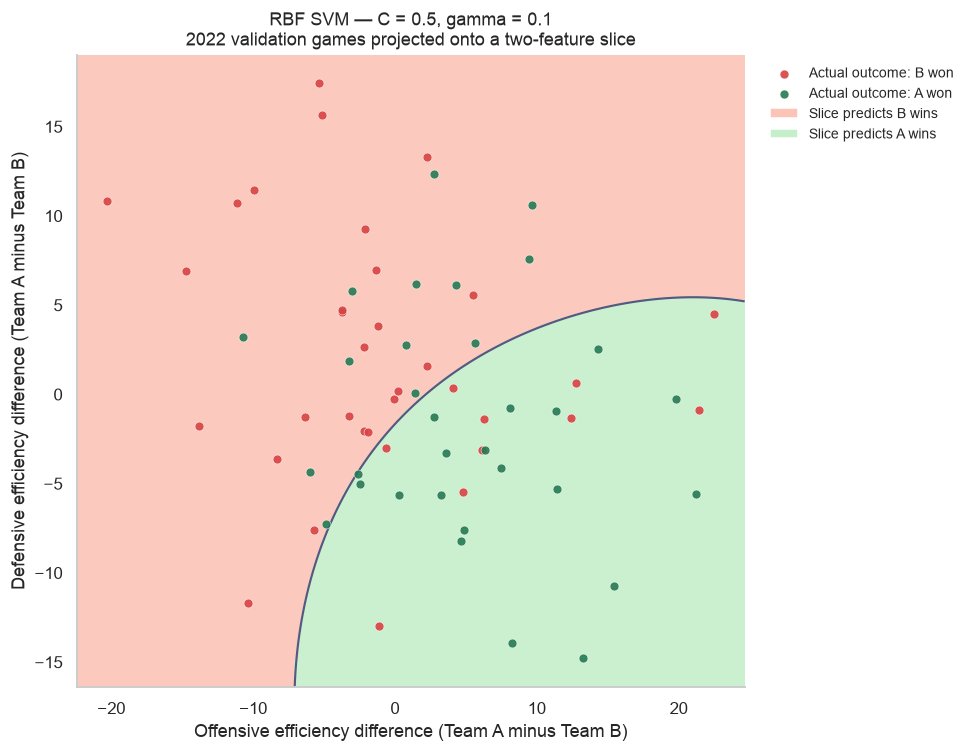

Background: seed difference fixed at 0; tempo difference fixed at 0.30 (base-training medians).
Dots: actual outcomes for 67 validation games. Their seed and tempo values vary, so a dot in the opposite-colored region is not necessarily a full-model error.


In [27]:
SVM_EXAMPLE_YEAR = 2022
SVM_EXAMPLE_SEED = 522
svm_selected_row = model_results["RBF SVM"][3].iloc[0]
svm_example_params = CANDIDATES["RBF SVM"][int(svm_selected_row.candidate_id)]
svm_example_columns = FEATURE_SETS["Seeds + stats"]
svm_example_history = development.loc[development.Season.lt(SVM_EXAMPLE_YEAR)]
svm_example_train, svm_example_cal = chronological_parts(svm_example_history)
svm_example_model, svm_example_notes = fit_calibrated(
    svm_example_history, svm_example_columns, "RBF SVM", svm_example_params, SVM_EXAMPLE_SEED)
if svm_example_notes:
    print(svm_example_notes)

# Vary offense and defense; keep the other two inputs at base-training medians.
svm_fixed_inputs = svm_example_train[svm_example_columns].median()
# Use the validation feature range so every validation game can be displayed.
svm_example_valid = development.loc[development.Season.eq(SVM_EXAMPLE_YEAR)]
svm_x_limits = svm_example_valid.AdjOE_diff.agg(["min", "max"]).to_numpy()
svm_y_limits = svm_example_valid.AdjDE_diff.agg(["min", "max"]).to_numpy()
svm_x_pad = (svm_x_limits[1] - svm_x_limits[0]) * 0.05
svm_y_pad = (svm_y_limits[1] - svm_y_limits[0]) * 0.05
svm_x, svm_y = np.meshgrid(
    np.linspace(svm_x_limits[0] - svm_x_pad, svm_x_limits[1] + svm_x_pad, 220),
    np.linspace(svm_y_limits[0] - svm_y_pad, svm_y_limits[1] + svm_y_pad, 220))
svm_grid = pd.DataFrame({c: np.full(svm_x.size, svm_fixed_inputs[c]) for c in svm_example_columns})
svm_grid["AdjOE_diff"], svm_grid["AdjDE_diff"] = svm_x.ravel(), svm_y.ravel()
svm_surface_p = svm_example_model.predict_proba(svm_grid)[:, list(svm_example_model.classes_).index(1)].reshape(svm_x.shape)

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(9, 7))
region_colors = ["#FBC4B7", "#C5EFCB"]
ax.contourf(svm_x, svm_y, (svm_surface_p >= 0.5).astype(int),
            levels=[-0.5, 0.5, 1.5], cmap=ListedColormap(region_colors), alpha=0.9)
if svm_surface_p.min() < 0.5 < svm_surface_p.max():
    ax.contour(svm_x, svm_y, svm_surface_p, levels=[0.5], colors="#535980", linewidths=1.4)
for outcome, color, label in [(0, "#D84242", "Actual outcome: B won"),
                              (1, "#267A53", "Actual outcome: A won")]:
    games_to_plot = svm_example_valid.loc[svm_example_valid.y_true.eq(outcome)]
    ax.scatter(games_to_plot.AdjOE_diff, games_to_plot.AdjDE_diff,
               color=color, s=34, alpha=0.9, edgecolors="white", linewidths=0.35, label=label, zorder=3)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(facecolor=region_colors[0], label="Slice predicts B wins"),
            Patch(facecolor=region_colors[1], label="Slice predicts A wins")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
ax.set(xlabel="Offensive efficiency difference (Team A minus Team B)",
       ylabel="Defensive efficiency difference (Team A minus Team B)",
       title=f"RBF SVM — C = {svm_example_params['C']:g}, gamma = {svm_example_params['gamma']}\n"
             f"{SVM_EXAMPLE_YEAR} validation games projected onto a two-feature slice")
ax.grid(False)
fig.tight_layout()
fig.savefig(OUT / "rbf_svm_decision_surface_2022.png", bbox_inches="tight")
plt.show()
print(f"Background: seed difference fixed at {svm_fixed_inputs['Seed_diff']:g}; "
      f"tempo difference fixed at {svm_fixed_inputs['AdjTempo_diff']:.2f} (base-training medians).")
print(f"Dots: actual outcomes for {len(svm_example_valid)} validation games. "
      "Their seed and tempo values vary, so a dot in the opposite-colored region is not necessarily a full-model error.")


## Model Implementation — Random Forest

- **Method:** An ensemble of 200 decision trees.
- **Library:** [`sklearn.ensemble.RandomForestClassifier`](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.RandomForestClassifier.html); not implemented from scratch.
- **Inputs:** the same four A-minus-B differences; fitting also requires the observed winner. Prediction does not require the outcome.
- **Preprocessing:** median imputation; no scaling for trees. All methods use separate chronological sigmoid calibration.
- **Configurations:** Test maximum depth = 3 or unlimited, crossed with minimum samples per leaf = 5 or 10. These settings control how complex each tree can become.

### 1. Define configurations

In [28]:
def build_random_forest(params, seed):
    return RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=seed, **params)

MODEL_BUILDERS['Random forest'] = build_random_forest
CANDIDATES['Random forest'] = [{"max_depth": d, "min_samples_leaf": l} for d, l in [(3, 10), (None, 10), (3, 5), (None, 5)]]
if MODE == "quick":
    CANDIDATES['Random forest'] = CANDIDATES['Random forest'][:2]
# Format the display only; keep None in the estimator's configuration.
rf_configurations = pd.DataFrame(CANDIDATES['Random forest']).rename_axis("candidate_id")
rf_configurations["max_depth"] = rf_configurations["max_depth"].map(
    lambda depth: "Unlimited" if pd.isna(depth) else str(int(depth)))
display(rf_configurations)

,max_depth,min_samples_leaf
candidate_id,,
0,3,10
1,Unlimited,10
2,3,5
3,Unlimited,5


### 2. Fit and select

Fit each configuration on earlier seasons, calibrate on the next two, and evaluate on the validation season. Select the smallest average validation log loss.

In [29]:
# Display every configuration and highlight the one selected by validation log loss.
model_results['Random forest'] = tune_model('Random forest')


All Random forest configurations (mean validation results):


candidate_id,parameters,mean_log_loss,mean_brier,mean_accuracy,selection
0,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.568878,0.194076,0.682572,BEST — selected
1,"{""max_depth"": null, ""min_samples_leaf"": 10}",0.570242,0.194219,0.683567,
2,"{""max_depth"": 3, ""min_samples_leaf"": 5}",0.569164,0.194175,0.684577,
3,"{""max_depth"": null, ""min_samples_leaf"": 5}",0.572260,0.194569,0.696623,


Best configuration: {"max_depth": 3, "min_samples_leaf": 10} (candidate 0). Mean validation log loss: 0.568878. Selected using the lowest unrounded mean validation log loss; exact ties retain the lower ID.


### 3. Compare configurations

- Top: mean loss across validation seasons and runs for each configuration.
- Bottom: mean loss across runs, by validation season, for the selected configuration.
- Each bar aggregates tournament games, not individual teams. Values are printed to six decimals; smaller is better.

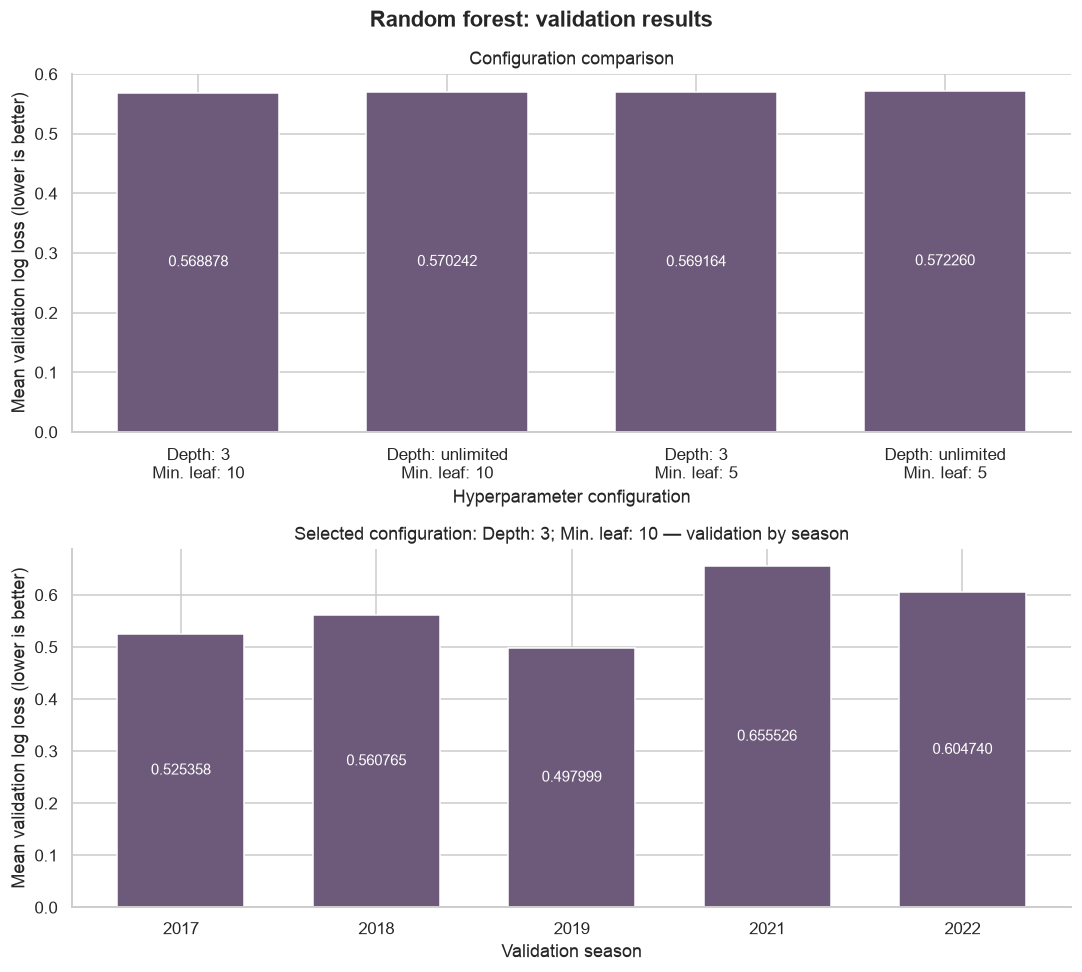

**Takeaway:** Depth: 3; Min. leaf: 10 is selected because it has the lowest average validation log loss (0.568878; ties use the lower configuration ID). Its seasonal mean log loss ranges from 0.497999 to 0.655526, showing how performance varies across tournaments. Bar labels show six decimals; selection uses full precision.

In [30]:
plot_model_validation('Random forest')

### Selected random forest: actual versus predicted winners

- Use the configuration selected across **all validation seasons**, evaluated on the **2022 validation fold**, with random seed **522**.
- Rows identify the actual winner; columns identify the predicted winner at probability threshold 0.5. Diagonal cells are correct predictions.
- Each cell shows a game count and percentage of its actual-outcome row. Each row adds to 100%, apart from rounding.

These predictions were made by the calibrated model trained on earlier seasons. “Actual B, predicted B” means B correctly predicted to beat A—not B playing itself. This is validation performance, not the final test result.


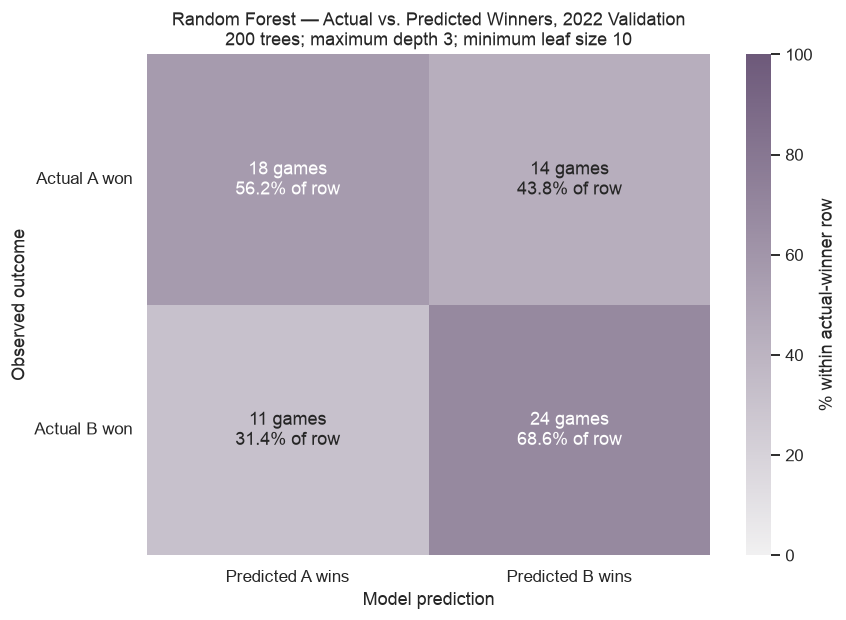

**Takeaway:** the selected random forest correctly predicted **42 of 67 games (62.7% accuracy)** in 2022, using run seed 522. It predicted A for 11 games actually won by B, and B for 14 games actually won by A. This summarizes one validation season, not the average across all seasons or the final test set.

In [31]:
RF_EXAMPLE_YEAR = 2022
RF_EXAMPLE_SEED = 522
rf_selected_row = model_results["Random forest"][3].iloc[0]
rf_selected_params = CANDIDATES["Random forest"][int(rf_selected_row.candidate_id)]
rf_validation_predictions = model_results["Random forest"][1]
rf_example = rf_validation_predictions.loc[
    rf_validation_predictions.candidate_id.eq(int(rf_selected_row.candidate_id))
    & rf_validation_predictions.season.eq(RF_EXAMPLE_YEAR)
    & rf_validation_predictions.run_seed.eq(RF_EXAMPLE_SEED)
    & rf_validation_predictions.feature_set.eq("Seeds + stats")
].copy()
assert not rf_example.empty and rf_example.game_id.is_unique
rf_predicted_winner = (rf_example.p_A_wins >= 0.5).astype(int)
rf_counts = confusion_matrix(rf_example.y_true, rf_predicted_winner, labels=[1, 0])
rf_row_totals = rf_counts.sum(axis=1, keepdims=True)
rf_row_percent = np.divide(rf_counts * 100, rf_row_totals,
                           out=np.zeros_like(rf_counts, dtype=float), where=rf_row_totals != 0)
rf_annotations = np.array([[f"{rf_counts[i, j]} games\n{rf_row_percent[i, j]:.1f}% of row"
                            for j in range(2)] for i in range(2)])
rf_depth_label = "Unlimited" if rf_selected_params["max_depth"] is None else str(rf_selected_params["max_depth"])
fig, ax = plt.subplots(figsize=(8, 5.8))
sns.heatmap(rf_row_percent, annot=rf_annotations, fmt="", vmin=0, vmax=100,
            cmap=sns.light_palette("#6D597A", as_cmap=True),
            cbar_kws={"label": "% within actual-winner row"},
            xticklabels=["Predicted A wins", "Predicted B wins"],
            yticklabels=["Actual A won", "Actual B won"], ax=ax)
ax.set(title=f"Random Forest — Actual vs. Predicted Winners, {RF_EXAMPLE_YEAR} Validation\n"
             f"200 trees; maximum depth {rf_depth_label}; minimum leaf size {rf_selected_params['min_samples_leaf']}",
       xlabel="Model prediction", ylabel="Observed outcome")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(OUT / "random_forest_confusion_2022.png", bbox_inches="tight")
plt.show()
rf_correct = int(np.trace(rf_counts))
rf_total = len(rf_example)
display(Markdown(f"**Takeaway:** the selected random forest correctly predicted **{rf_correct} of {rf_total} games "
                 f"({rf_correct / rf_total:.1%} accuracy)** in 2022, using run seed {RF_EXAMPLE_SEED}. "
                 f"It predicted A for {rf_counts[1, 0]} games actually won by B, and B for "
                 f"{rf_counts[0, 1]} games actually won by A. This summarizes one validation season, "
                 "not the average across all seasons or the final test set."))


## Model Implementation — Neural Network (MLP)

- **Method:** a multilayer perceptron (MLP), a feed-forward neural network.
- **Library:** [`sklearn.neural_network.MLPClassifier`](https://scikit-learn.org/1.7/modules/generated/sklearn.neural_network.MLPClassifier.html); not implemented from scratch.
- **Inputs:** the same four A-minus-B differences and the observed winner during fitting.
- **Preprocessing:** median imputation, standardization, and separate chronological sigmoid calibration.
- **Configurations:** compare **one or two hidden layers**, with **8 units in every hidden layer**, crossed with `alpha = 0.1` or `1.0`. Alpha controls L2 regularization.
- **Architecture:** `(8,)` means one layer of 8 units; `(8, 8)` means two layers of 8 units each. Width stays fixed, but adding a layer increases the total number of trainable parameters.

### 1. Define configurations


In [32]:
def build_mlp(params, seed):
    return MLPClassifier(max_iter=600, solver="adam", learning_rate_init=0.001, early_stopping=False, random_state=seed, **params)

MODEL_BUILDERS['Neural network (MLP)'] = build_mlp
CANDIDATES['Neural network (MLP)'] = [{"hidden_layer_sizes": h, "alpha": a} for h, a in [((8,), 0.1), ((8, 8), 0.1), ((8,), 1.0), ((8, 8), 1.0)]]
if MODE == "quick":
    CANDIDATES['Neural network (MLP)'] = CANDIDATES['Neural network (MLP)'][:2]
nn_configurations = pd.DataFrame(CANDIDATES['Neural network (MLP)']).rename_axis("candidate_id")
nn_configurations["hidden_layers"] = nn_configurations.hidden_layer_sizes.map(len)
nn_configurations["units_per_layer"] = 8
display(nn_configurations[["hidden_layers", "units_per_layer", "alpha"]])

,hidden_layers,units_per_layer,alpha
candidate_id,,,
0,1,8,0.1
1,2,8,0.1
2,1,8,1.0
3,2,8,1.0


### 2. Fit and select

Fit each configuration on earlier seasons, calibrate on the next two, and evaluate on the validation season. Select the smallest average validation log loss.

In [33]:
# Display every configuration and highlight the one selected by validation log loss.
model_results['Neural network (MLP)'] = tune_model('Neural network (MLP)')


All Neural network (MLP) configurations (mean validation results):


candidate_id,parameters,mean_log_loss,mean_brier,mean_accuracy,selection
0,"{""hidden_layer_sizes"": [8], ""alpha"": 0.1}",0.576581,0.197363,0.682527,
1,"{""hidden_layer_sizes"": [8, 8], ""alpha"": 0.1}",0.572750,0.195597,0.703528,
2,"{""hidden_layer_sizes"": [8], ""alpha"": 1.0}",0.575629,0.196982,0.686537,
3,"{""hidden_layer_sizes"": [8, 8], ""alpha"": 1.0}",0.572339,0.195407,0.701583,BEST — selected


Best configuration: {"hidden_layer_sizes": [8, 8], "alpha": 1.0} (candidate 3). Mean validation log loss: 0.572339. Selected using the lowest unrounded mean validation log loss; exact ties retain the lower ID.


### 3. Compare configurations

- Top: mean loss across validation seasons and runs for each configuration.
- Bottom: mean loss across runs, by validation season, for the selected configuration.
- Each bar aggregates tournament games, not individual teams. Values are printed to six decimals; smaller is better.

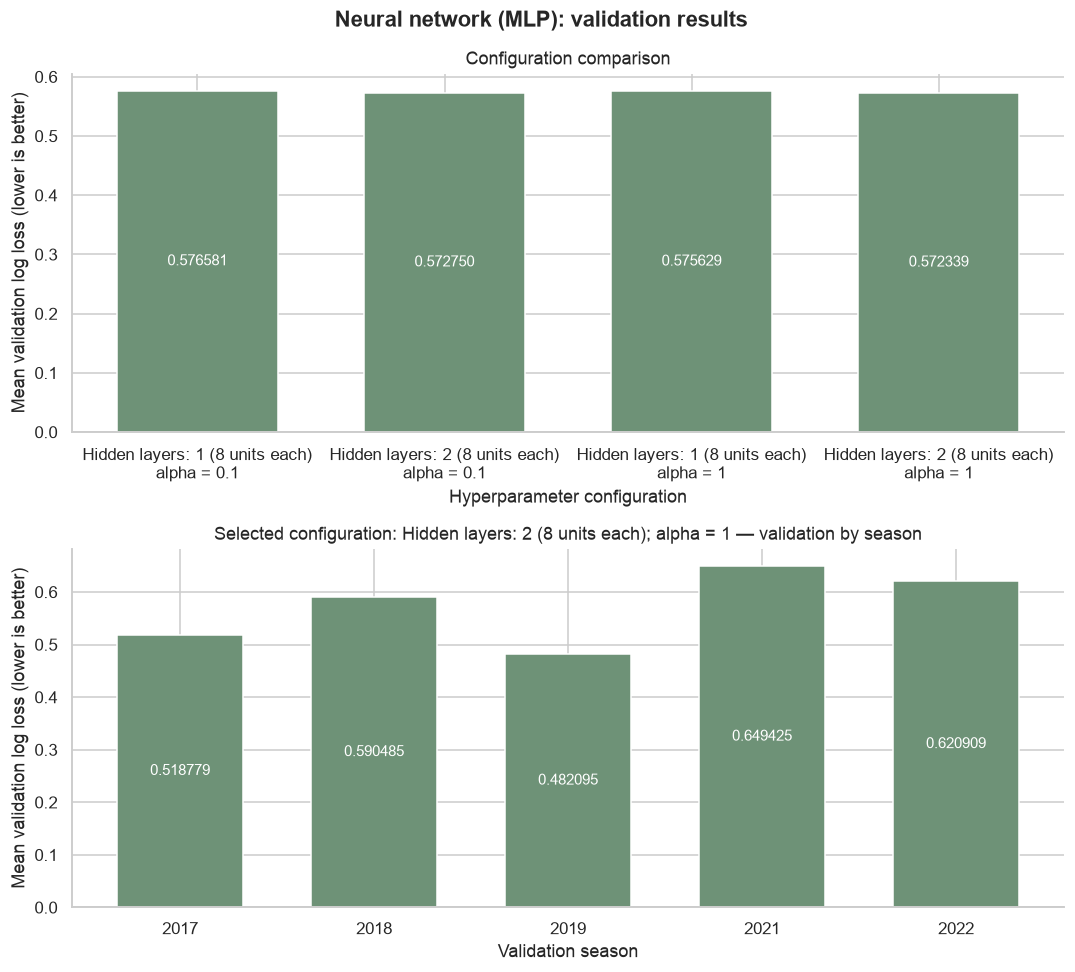

**Takeaway:** Hidden layers: 2 (8 units each); alpha = 1 is selected because it has the lowest average validation log loss (0.572339; ties use the lower configuration ID). Its seasonal mean log loss ranges from 0.482095 to 0.649425, showing how performance varies across tournaments. Bar labels show six decimals; selection uses full precision.

In [34]:
plot_model_validation('Neural network (MLP)')

### Selected neural network: training progress

- Use the configuration selected across all validation seasons, illustrated with the **2022 validation fit** and random seed **522**.
- **Horizontal axis:** epoch (one pass through the base-training data). **Vertical axis:** scikit-learn's recorded training objective, including L2 regularization.
- Adam adjusts the network weights during training. A decreasing curve shows optimization progress; it does not prove good performance on unseen games.

This curve is from base-model training before sigmoid calibration. Its regularized training objective is not directly comparable to calibrated validation log loss.


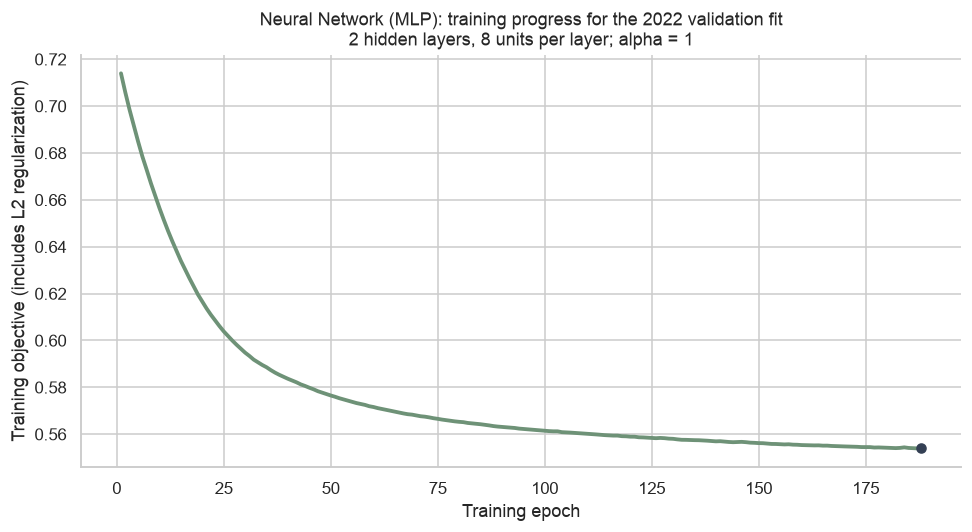

**Takeaway:** the recorded training objective changed from **0.713991** to **0.553905** over **188 epochs**. This describes optimization on training data; the validation scores and predictions below assess performance on later games.

Base training: 2003–2018; calibration seasons: [2019, 2021]; validation: 2022.


In [35]:
NN_EXAMPLE_YEAR = 2022
NN_EXAMPLE_SEED = 522
nn_selected_row = model_results["Neural network (MLP)"][3].iloc[0]
nn_example_params = CANDIDATES["Neural network (MLP)"][int(nn_selected_row.candidate_id)]
nn_example_columns = FEATURE_SETS["Seeds + stats"]
nn_example_history = development.loc[development.Season.lt(NN_EXAMPLE_YEAR)]
nn_example_train, nn_example_cal = chronological_parts(nn_example_history)
nn_example_valid = development.loc[development.Season.eq(NN_EXAMPLE_YEAR)]
nn_example_model = make_base_model("Neural network (MLP)", nn_example_params, NN_EXAMPLE_SEED)
nn_example_model.fit(nn_example_train[nn_example_columns], nn_example_train.y_true)
nn_estimator = nn_example_model.named_steps["model"]
nn_losses = np.asarray(nn_estimator.loss_curve_)
nn_architecture = (f"{len(nn_example_params['hidden_layer_sizes'])} hidden layers, "
                   f"{nn_example_params['hidden_layer_sizes'][0]} units per layer; alpha = {nn_example_params['alpha']:g}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(1, len(nn_losses) + 1), nn_losses, color="#6E9277", linewidth=2.5)
ax.scatter([len(nn_losses)], [nn_losses[-1]], color="#344054", s=35, zorder=3)
ax.set(title=f"Neural Network (MLP): training progress for the {NN_EXAMPLE_YEAR} validation fit\n{nn_architecture}",
       xlabel="Training epoch", ylabel="Training objective (includes L2 regularization)")
fig.tight_layout()
fig.savefig(OUT / "neural_network_training_loss_2022.png", bbox_inches="tight")
plt.show()
display(Markdown(f"**Takeaway:** the recorded training objective changed from **{nn_losses[0]:.6f}** "
                 f"to **{nn_losses[-1]:.6f}** over **{nn_estimator.n_iter_} epochs**. "
                 "This describes optimization on training data; the validation scores and predictions below assess performance on later games."))
print(f"Base training: {nn_example_train.Season.min()}–{nn_example_train.Season.max()}; "
      f"calibration seasons: {sorted(nn_example_cal.Season.unique().tolist())}; validation: {NN_EXAMPLE_YEAR}.")


### Selected neural network: actual versus predicted winners

- Apply sigmoid calibration using the reserved historical seasons, then predict the **67 games in the 2022 validation season**.
- **Rows:** actual winner. **Columns:** predicted winner at probability threshold 0.5. Diagonal cells are correct predictions.
- Each cell shows a count and percentage of its actual-winner row; each row sums to 100%, apart from rounding.

The configuration is selected across all validation seasons, not reselected for 2022. These are validation results, not final test results.


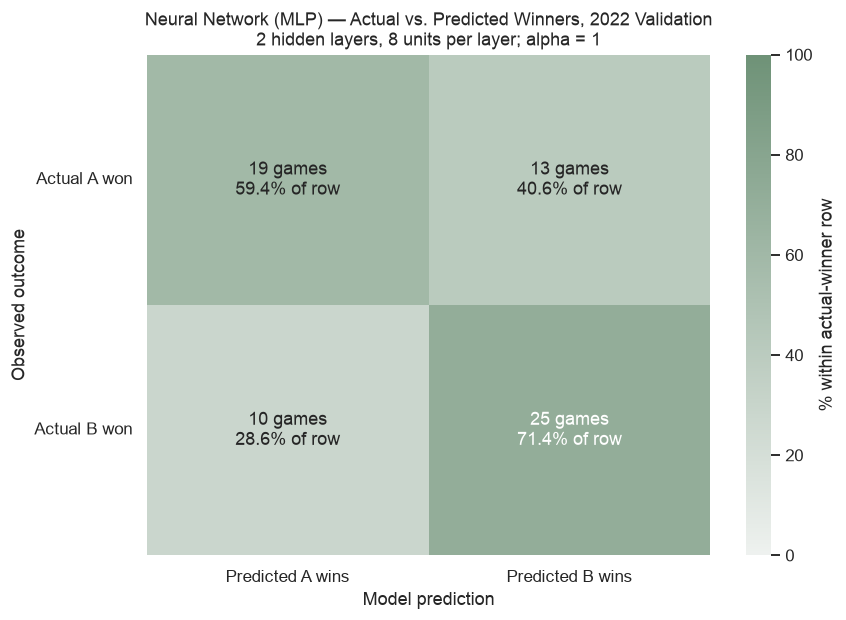

**Takeaway:** the calibrated neural network correctly predicted **44 of 67 games (65.7% accuracy)** in 2022, using random seed 522. It predicted A for 10 games actually won by B, and B for 13 games actually won by A. This illustrates one validation season rather than overall test performance.

In [36]:
nn_example_calibrated = CalibratedClassifierCV(FrozenEstimator(nn_example_model), method="sigmoid")
nn_example_calibrated.fit(nn_example_cal[nn_example_columns], nn_example_cal.y_true)
nn_example_probability = nn_example_calibrated.predict_proba(nn_example_valid[nn_example_columns])[
    :, list(nn_example_calibrated.classes_).index(1)]
nn_example_predicted = (nn_example_probability >= 0.5).astype(int)
nn_counts = confusion_matrix(nn_example_valid.y_true, nn_example_predicted, labels=[1, 0])
nn_row_totals = nn_counts.sum(axis=1, keepdims=True)
nn_row_percent = np.divide(nn_counts * 100, nn_row_totals,
                           out=np.zeros_like(nn_counts, dtype=float), where=nn_row_totals != 0)
nn_annotations = np.array([[f"{nn_counts[i, j]} games\n{nn_row_percent[i, j]:.1f}% of row"
                            for j in range(2)] for i in range(2)])
fig, ax = plt.subplots(figsize=(8, 5.8))
sns.heatmap(nn_row_percent, annot=nn_annotations, fmt="", vmin=0, vmax=100,
            cmap=sns.light_palette("#6E9277", as_cmap=True),
            cbar_kws={"label": "% within actual-winner row"},
            xticklabels=["Predicted A wins", "Predicted B wins"],
            yticklabels=["Actual A won", "Actual B won"], ax=ax)
ax.set(title=f"Neural Network (MLP) — Actual vs. Predicted Winners, {NN_EXAMPLE_YEAR} Validation\n{nn_architecture}",
       xlabel="Model prediction", ylabel="Observed outcome")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(OUT / "neural_network_confusion_2022.png", bbox_inches="tight")
plt.show()
nn_correct, nn_total = int(np.trace(nn_counts)), len(nn_example_valid)
display(Markdown(f"**Takeaway:** the calibrated neural network correctly predicted **{nn_correct} of {nn_total} "
                 f"games ({nn_correct / nn_total:.1%} accuracy)** in 2022, using random seed {NN_EXAMPLE_SEED}. "
                 f"It predicted A for {nn_counts[1, 0]} games actually won by B, and B for {nn_counts[0, 1]} "
                 "games actually won by A. This illustrates one validation season rather than overall test performance."))


### Neural network results summary

For the selected **two-hidden-layer network, with 8 units per layer and alpha = 1.0**, illustrated using the 2022 validation fold and random seed 522:

- **Training-loss curve:** the regularized training objective decreased from **0.713991 to 0.553905** over **188 epochs**.
- **Validation confusion matrix:** the calibrated model correctly predicted **44 of 67 games (65.7%)**. The matrix shows counts and percentages within each actual-winner row.

The loss curve describes training progress; the confusion matrix describes performance on later validation games. These are not final test results.


## Final Comparison

### Validation model-selection table

Rows are sorted by **increasing mean validation log loss**, with model name breaking ties. Each row shows the selected configuration, its hyperparameters, average validation log loss, Brier score, and accuracy. See the column definitions above. The test set is not used to choose these settings.

In [37]:
assert set(model_results) == set(MODEL_NAMES), "Run all four model sections first."
cv_scores = pd.concat([model_results[m][0] for m in MODEL_NAMES], ignore_index=True)
cv_predictions = pd.concat([model_results[m][1] for m in MODEL_NAMES], ignore_index=True)
candidate_scores = pd.concat([model_results[m][2] for m in MODEL_NAMES], ignore_index=True)
selected = pd.concat([model_results[m][3] for m in MODEL_NAMES], ignore_index=True)
cv_scores.to_csv(OUT / "development_scores.csv", index=False)
cv_predictions.to_csv(OUT / "development_predictions.csv", index=False)
candidate_scores.to_csv(OUT / "candidate_scores.csv", index=False)
selected.to_csv(OUT / "selected_parameters.csv", index=False)
display(selected.sort_values(["mean_log_loss", "model"]).round(4))

,model,feature_set,candidate_id,mean_log_loss,mean_brier,mean_accuracy,parameters
0,Logistic regression,Seeds + stats,3,0.5622,0.1923,0.7006,"{""C"": 10.0}"
2,Random forest,Seeds + stats,0,0.5689,0.1941,0.6826,"{""max_depth"": 3, ""min_samples_leaf"": 10}"
3,Neural network (MLP),Seeds + stats,3,0.5723,0.1954,0.7016,"{""hidden_layer_sizes"": [8, 8], ""alpha"": 1.0}"
1,RBF SVM,Seeds + stats,2,0.5792,0.1977,0.7066,"{""C"": 0.5, ""gamma"": 0.1}"


### Validation comparison

Bars summarize the selected configuration for each method over the same validation seasons and runs. Lower log loss is better. These are model-selection results, not final test results.

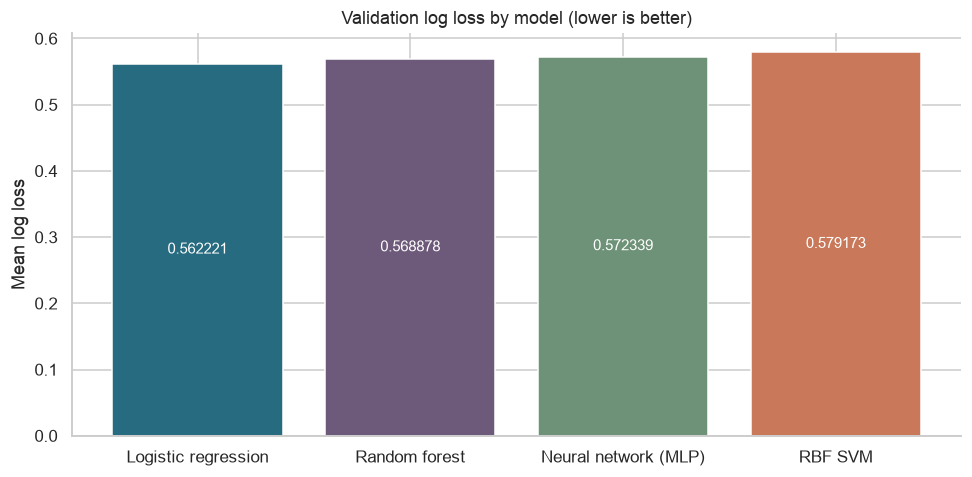

In [38]:
ranked = selected.sort_values(["mean_log_loss", "model"])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(ranked.model, ranked.mean_log_loss, color=[MODEL_COLORS[m] for m in ranked.model])
label_bars(ax)
ax.set(title="Validation log loss by model (lower is better)", ylabel="Mean log loss")
fig.tight_layout(); fig.savefig(OUT / "development_comparison.png", bbox_inches="tight"); plt.show()

### Test evaluation

- **Test set:** 201 tournament games from 2023–2025, excluded from hyperparameter selection.
- Use the validation-selected configurations. Fit base models on 2003–2019 games and calibrate on 2021–2022 games.
- Evaluate the fitted models on all three test seasons without retraining between seasons.
- Tables, predictions, and figures are saved in the `Results:` folder printed in Experiment settings.


In [39]:
def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

In [42]:
manifest = {
    "run_id": RUN_ID, "mode": MODE, "final_test_enabled": RUN_FINAL_TEST,
    "years": [START_YEAR, END_YEAR], "validation_years": VALIDATION_YEARS,
    "test_years": TEST_YEARS, "calibration_seasons": CALIBRATION_SEASONS,
    "run_seeds": RUN_SEEDS, "features": FEATURE_SETS,
    "manual_team_ids": MANUAL_TEAM_IDS,
    "packages": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "inputs": {k: {"filename": p.name, "sha256": sha256(p)} for k, p in paths.items() if p},
    "selected": selected.to_dict(orient="records"),
    "candidate_grids": CANDIDATES,
}
(OUT / "experiment_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Manifest saved.")
if not RUN_FINAL_TEST:
    display(Markdown("> **test evaluation is disabled for this run.** Development results are available. "
                     "To perform the prespecified final evaluation, use full mode, enable RUN_FINAL_TEST, and rerun all cells."))
elif MODE != "full":
    display(Markdown("> **Quick-mode test:** useful for debugging only. Do not report it as the full study."))

Manifest saved.


In [43]:
final_predictions = pd.DataFrame()
final_fit_records = []
if RUN_FINAL_TEST:
    test = matchups.loc[matchups.Season.isin(TEST_YEARS)].copy()
    assert development.Season.max() < test.Season.min()
    assert set(development.game_id).isdisjoint(test.game_id)
    saved_predictions = []
    for row in selected.itertuples(index=False):
        params = CANDIDATES[row.model][int(row.candidate_id)]
        columns = FEATURE_SETS[row.feature_set]
        for seed in RUN_SEEDS:
            fitted, notes = fit_calibrated(development, columns, row.model, params, seed)
            p = fitted.predict_proba(test[columns])[:, list(fitted.classes_).index(1)]
            saved_predictions.append(prediction_rows(test, p, row.model, row.feature_set, seed))
            final_fit_records.append({"model": row.model, "feature_set": row.feature_set,
                                      "run_seed": seed, "warnings": notes})
    final_predictions = pd.concat(saved_predictions, ignore_index=True)
    final_predictions.to_csv(OUT / "test_predictions.csv", index=False)
    pd.DataFrame(final_fit_records).to_csv(OUT / "final_fit_records.csv", index=False)
    print(f"Saved {len(final_predictions):,} predictions across all model/feature/run combinations.")


Saved 2,412 predictions across all model/feature/run combinations.


### Final test results (2023–2025)

**Sorting:** increasing test `log_loss_mean` (lower is better); model name breaks ties. This is a descriptive test ranking, not another selection step.

**Averages:** for each run seed, calculate metrics over all 201 games. Then average those three run-level scores. `*_sd` is the sample standard deviation across the three runs, not a confidence interval for future tournaments.

| Column | Meaning |
|:--|:--|
| `model`, `parameters` | Method and validation-selected configuration |
| `log_loss_mean`, `log_loss_sd` | Mean and standard deviation of test log loss; lower mean is better |
| `brier_mean`, `brier_sd` | Mean and standard deviation of squared probability error; lower mean is better |
| `accuracy_mean`, `accuracy_sd` | Mean and standard deviation of accuracy, expressed as a fraction (0.70 = 70%) |
| `test_games`, `runs` | Number of unique evaluated games and repeated fits |

All four models use the same seeds-plus-statistics inputs. Values are displayed to four decimals, with six decimals for standard deviations to reveal small differences.

In [42]:
if RUN_FINAL_TEST:
    pooled_records, season_records = [], []
    for (name, feature_set, seed), group in final_predictions.groupby(["model", "feature_set", "run_seed"]):
        pooled_records.append({"model": name, "feature_set": feature_set, "run_seed": seed,
                               **evaluate(group.y_true, group.p_A_wins)})
        for year, season_group in group.groupby("season"):
            season_records.append({"model": name, "feature_set": feature_set, "run_seed": seed,
                                   "season": year, **evaluate(season_group.y_true, season_group.p_A_wins)})
    pooled_scores = pd.DataFrame(pooled_records)
    season_scores = pd.DataFrame(season_records)
    summary = pooled_scores.groupby("model", as_index=False).agg(
        log_loss_mean=("log_loss", "mean"), log_loss_sd=("log_loss", "std"),
        brier_mean=("brier", "mean"), brier_sd=("brier", "std"),
        accuracy_mean=("accuracy", "mean"), accuracy_sd=("accuracy", "std"))
    summary = summary.merge(selected[["model", "parameters"]], on="model", validate="one_to_one")
    summary["test_games"], summary["runs"] = test.game_id.nunique(), len(RUN_SEEDS)
    summary = summary.sort_values(["log_loss_mean", "model"]).reset_index(drop=True)
    formats = {c: "{:.6f}" if c.endswith("_sd") else "{:.4f}" for c in summary.select_dtypes("float").columns}
    display(summary.style.format(formats))
    summary.to_csv(OUT / "test_summary.csv", index=False)
    pooled_scores.to_csv(OUT / "test_pooled_scores.csv", index=False)
    season_scores.to_csv(OUT / "test_season_scores.csv", index=False)
    print(f"Final result files: {OUT}")
else:
    print("Test evaluation is disabled. Set RUN_FINAL_TEST = True and rerun all cells to generate test results.")

,model,log_loss_mean,log_loss_sd,brier_mean,brier_sd,accuracy_mean,accuracy_sd,parameters,test_games,runs
0,Logistic regression,0.5791,0.000000,0.1983,0.000000,0.6667,0.000000,"{""C"": 10.0}",201,3
1,Random forest,0.5859,0.000706,0.2006,0.000377,0.6650,0.005745,"{""max_depth"": 3, ""min_samples_leaf"": 10}",201,3
2,Neural network (MLP),0.5870,0.005976,0.2009,0.002469,0.6733,0.005745,"{""hidden_layer_sizes"": [8, 8], ""alpha"": 1.0}",201,3
3,RBF SVM,0.5984,0.000000,0.2052,0.000000,0.6915,0.000000,"{""C"": 0.5, ""gamma"": 0.1}",201,3


Final result files: /Users/saathanachandrakumar/Documents/syde_522_project/march-madness/results/20261122T231801609525Z_full


### Test-score comparison

- Bar heights are the mean across three repeated fits; labels show six decimal places.
- Error bars are **standard deviations for every model**. Zero or very small deviations may be invisible. Logistic regression and this SVM setup produce identical scores across runs; forest and MLP can vary.
- Refer to the table for exact standard deviations. These bars measure initialization variability, not uncertainty from sampling future tournaments.

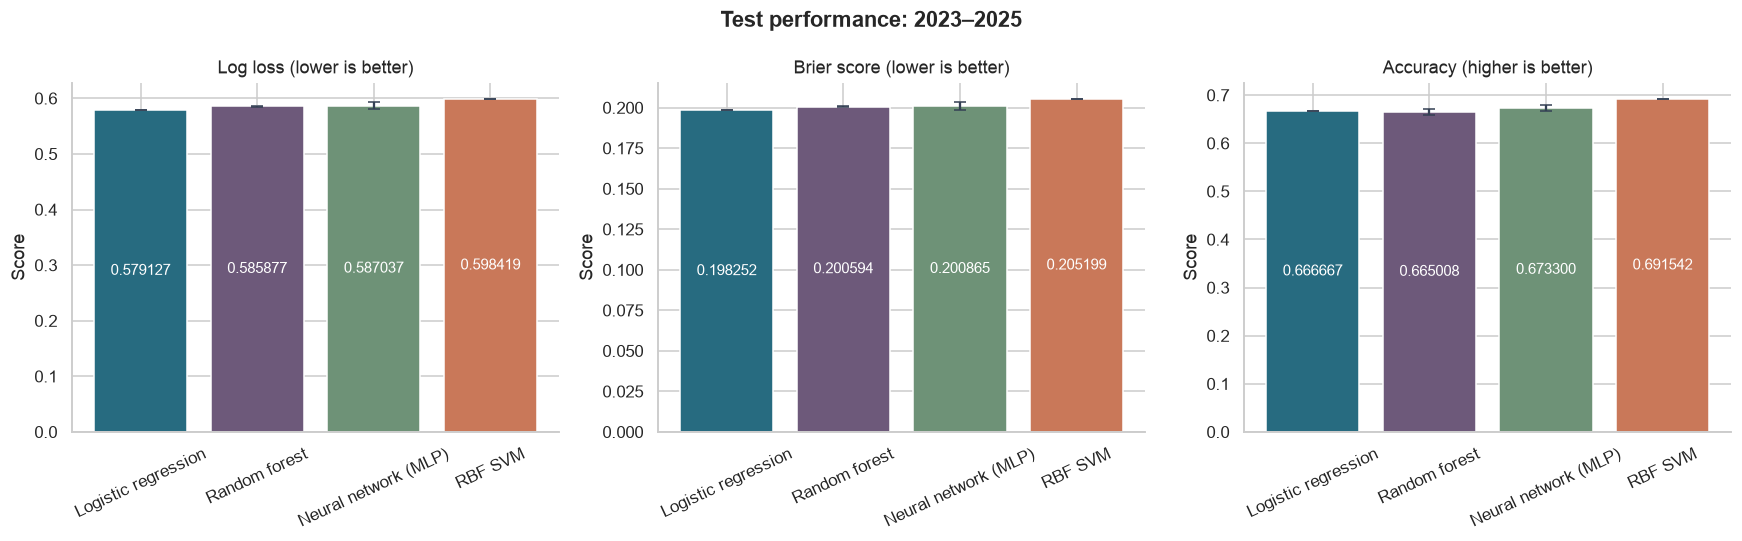

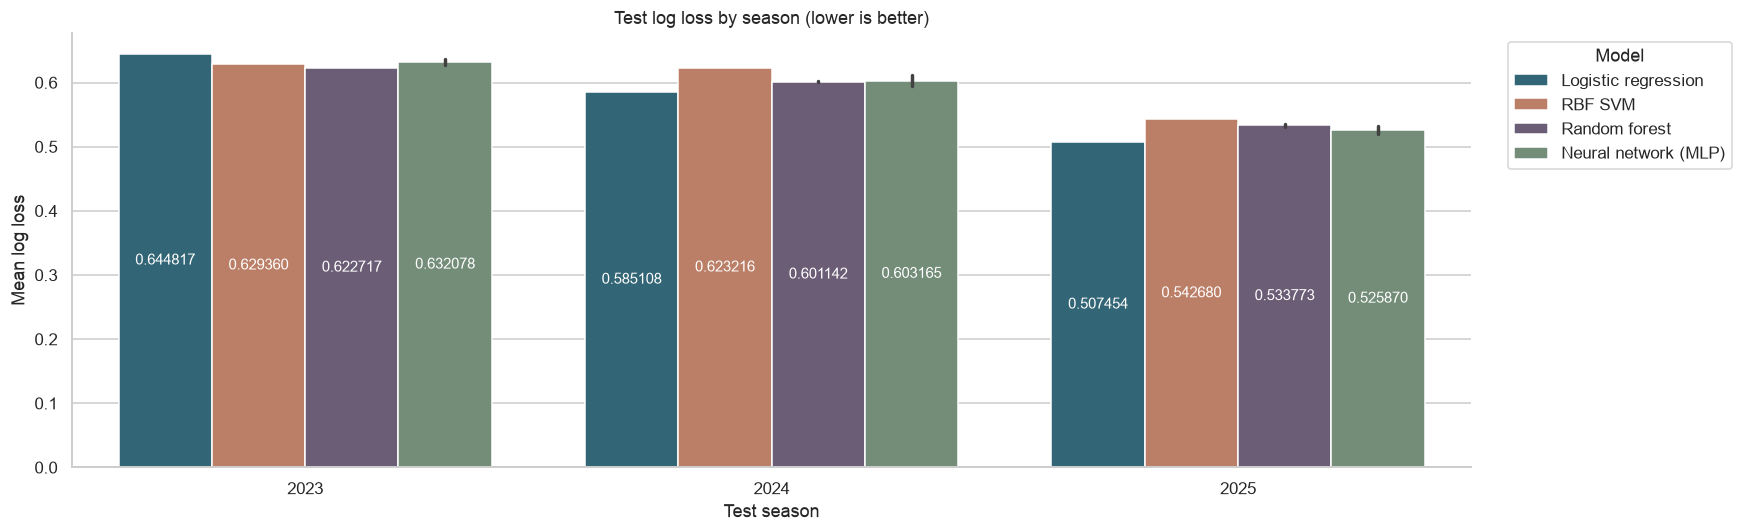

In [43]:
if RUN_FINAL_TEST:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, metric, title in zip(axes, ["log_loss", "brier", "accuracy"],
                                 ["Log loss (lower is better)", "Brier score (lower is better)", "Accuracy (higher is better)"]):
        ax.bar(summary.model, summary[f"{metric}_mean"], yerr=summary[f"{metric}_sd"].fillna(0),
               capsize=4, color=[MODEL_COLORS[m] for m in summary.model], ecolor="#344054")
        label_bars(ax)
        ax.set(title=title, ylabel="Score")
        ax.tick_params(axis="x", rotation=25)
    fig.suptitle("Test performance: 2023–2025", fontweight="bold")
    fig.tight_layout(); fig.savefig(OUT / "test_metrics.png", bbox_inches="tight"); plt.show()

    fig, ax = plt.subplots(figsize=(16, 5))
    sns.barplot(data=season_scores, x="season", y="log_loss", hue="model", hue_order=MODEL_NAMES,
                palette=MODEL_COLORS, order=TEST_YEARS, errorbar="sd", ax=ax)
    label_bars(ax)
    ax.set(title="Test log loss by season (lower is better)", xlabel="Test season", ylabel="Mean log loss")
    ax.legend(title="Model", loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.tight_layout(); fig.savefig(OUT / "test_by_season.png", bbox_inches="tight"); plt.show()

### Probability reliability

- **Calibration:** among games assigned an 80% Team A win probability, roughly 80% should be won by Team A over many observations.
- The reliability plot groups test games into five probability bins. Horizontal axis: average predicted Team A win probability. Vertical axis: observed Team A win percentage. The diagonal represents agreement.
- These values do **not** add to 100%: they compare a prediction with its observed frequency. For a single game, `P(A wins) + P(B wins) = 100%`.
- Use this to assess probability reliability alongside accuracy. Small bins make the curve descriptive, not definitive. Calibration is fitted on earlier games, never on this test plot.
- All models below use the first run seed (522). The box-shaped probability histogram has been removed because it duplicated context without helping the comparison.

### Predicted versus actual winner

The outcome matrix uses the **validation-selected model**, with rows labelled *actual winner* and columns labelled *predicted winner*.

- “Actual B, predicted B” means the model correctly predicted that B would beat A—not B playing against itself.
- Each cell displays **a game count and percentage of its actual-outcome row**. Each row adds to 100% (apart from rounding); the entire matrix does not.
- Diagonal cells are correct predictions; off-diagonal cells are incorrect predictions.

The accompanying error table lists the ten incorrect predictions with the largest assigned probability, using actual team names. It is an error description, not a reason to retune on test outcomes.

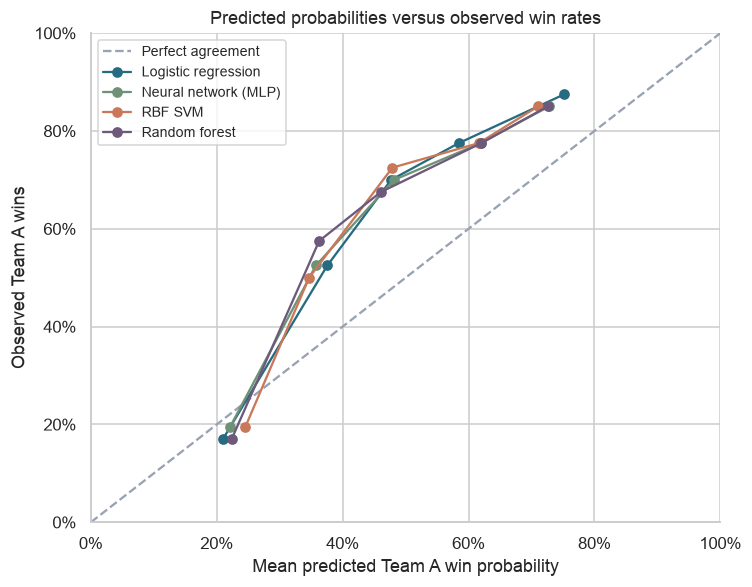

**Validation-selected model: Logistic regression.** Predictions shown use run seed 522.

,season,NameA,NameB,predicted_winner,actual_winner,assigned_probability
25,2023,Fairleigh Dickinson,Purdue,Purdue,Fairleigh Dickinson,94.4%
88,2024,Auburn,Yale,Auburn,Yale,74.9%
5,2023,Arizona,Princeton,Arizona,Princeton,72.8%
63,2023,Miami FL,Texas,Texas,Miami FL,72.2%
81,2024,Kentucky,Oakland,Kentucky,Oakland,71.7%
12,2023,Furman,Virginia,Virginia,Furman,71.6%
170,2025,Arkansas,St. John's,St. John's,Arkansas,71.6%
143,2025,Drake,Missouri,Missouri,Drake,71.1%
98,2024,James Madison,Wisconsin,Wisconsin,James Madison,69.1%
124,2024,Duke,Houston,Houston,Duke,68.5%


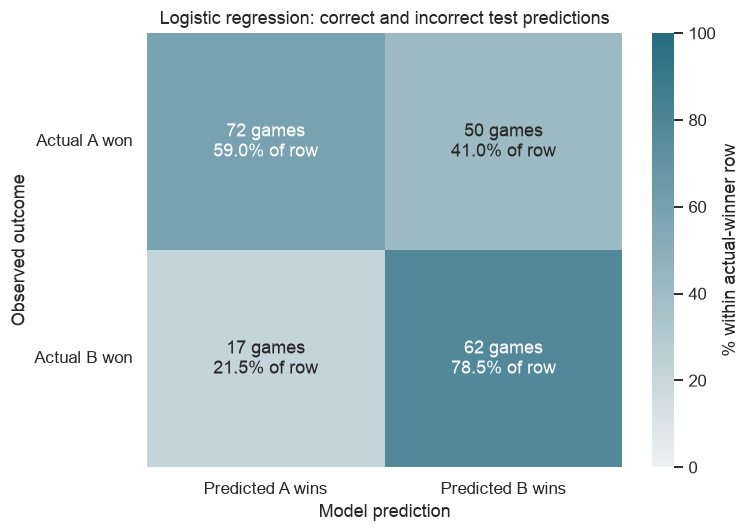

In [44]:
if RUN_FINAL_TEST:
    primary = final_predictions.loc[final_predictions.run_seed.eq(RUN_SEEDS[0])]
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.plot([0, 100], [0, 100], "--", color="#98A2B3", label="Perfect agreement")
    for name, group in primary.groupby("model"):
        observed, predicted = calibration_curve(group.y_true, group.p_A_wins, n_bins=5, strategy="quantile")
        ax.plot(predicted * 100, observed * 100, marker="o", color=MODEL_COLORS[name], label=name)
    ax.set(title="Predicted probabilities versus observed win rates", xlabel="Mean predicted Team A win probability",
           ylabel="Observed Team A wins", xlim=(0, 100), ylim=(0, 100))
    ax.xaxis.set_major_formatter(PercentFormatter(100)); ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend(fontsize=9); fig.tight_layout()
    fig.savefig(OUT / "calibration.png", bbox_inches="tight"); plt.show()

    focus_name = selected.sort_values(["mean_log_loss", "model"]).iloc[0].model
    errors = primary.loc[primary.model.eq(focus_name)].copy()
    errors["predicted_A_win"] = (errors.p_A_wins >= 0.5).astype(int)
    errors["predicted_winner"] = np.where(errors.predicted_A_win.eq(1), errors.NameA, errors.NameB)
    errors["actual_winner"] = np.where(errors.y_true.eq(1), errors.NameA, errors.NameB)
    errors["assigned_probability"] = np.maximum(errors.p_A_wins, 1-errors.p_A_wins)
    errors["wrong"] = errors.predicted_A_win.ne(errors.y_true)
    display(Markdown(f"**Validation-selected model: {focus_name}.** Predictions shown use run seed 522."))
    display(errors.loc[errors.wrong].sort_values("assigned_probability", ascending=False)[
        ["season", "NameA", "NameB", "predicted_winner", "actual_winner", "assigned_probability"]].head(10)
        .style.format({"assigned_probability": "{:.1%}"}))
    errors.to_csv(OUT / "error_analysis.csv", index=False)
    counts = confusion_matrix(errors.y_true, errors.predicted_A_win, labels=[1, 0])
    percentages = np.divide(counts * 100, counts.sum(axis=1, keepdims=True),
                            out=np.zeros_like(counts, dtype=float), where=counts.sum(axis=1, keepdims=True) != 0)
    annotations = np.array([[f"{counts[i,j]} games\n{percentages[i,j]:.1f}% of row" for j in range(2)] for i in range(2)])
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(percentages, annot=annotations, fmt="", cmap=sns.light_palette("#276B80", as_cmap=True),
                vmin=0, vmax=100, cbar_kws={"label": "% within actual-winner row"},
                xticklabels=["Predicted A wins", "Predicted B wins"],
                yticklabels=["Actual A won", "Actual B won"], ax=ax)
    ax.set(title=f"{focus_name}: correct and incorrect test predictions", xlabel="Model prediction", ylabel="Observed outcome")
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout(); fig.savefig(OUT / "confusion_matrix.png", bbox_inches="tight"); plt.show()

### Interpretation and limitations

- Compare algorithms using test log loss, Brier score, and accuracy together; small differences do not establish statistical superiority.
- Report validation-selected hyperparameters, the three-run averages, and variability across seasons.
- With only three test tournaments, repeated random seeds do not create independent new tournaments.
- The current study compares four algorithms using the same four inputs; it does not measure the benefit of statistics relative to seeds alone.
- The neural-network architecture search was revised after test results had been inspected. Configuration selection still uses validation scores; the revised test results are a follow-up analysis, not a new independent evaluation.

### Sources

- [KenPom metric definitions](https://kenpom.com/blog/ratings-glossary/)
- [Supplied KenPom dataset](https://www.kaggle.com/datasets/jonathanpilafas/2024-march-madness-statistical-analysis), pre-tournament-labelled file; snapshot timing requires verification.
- [Kaggle tournament outcomes and team IDs](https://www.kaggle.com/competitions/march-machine-learning-mania-2026/data)
- [scikit-learn probability calibration](https://scikit-learn.org/1.7/modules/calibration.html)